In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Time series structure

## Cycles

In [2]:
sunspots = pd.read_csv('sunspots.csv')
sunspots.info()

<class 'pandas.DataFrame'>
RangeIndex: 3265 entries, 0 to 3264
Data columns (total 3 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         3265 non-null   int64  
 1   Date                               3265 non-null   str    
 2   Monthly Mean Total Sunspot Number  3265 non-null   float64
dtypes: float64(1), int64(1), str(1)
memory usage: 76.7 KB


In [3]:
sunspots

,Unnamed: 0,Date,Monthly Mean Total Sunspot Number
0,0,1749-01-31,96.7
1,1,1749-02-28,104.3
2,2,1749-03-31,116.7
3,3,1749-04-30,92.8
4,4,1749-05-31,141.7
...,...,...,...
3260,3260,2020-09-30,0.6
3261,3261,2020-10-31,14.4
3262,3262,2020-11-30,34.0
3263,3263,2020-12-31,21.8


In [4]:
sunspots['Date'] = pd.to_datetime(sunspots['Date'])

In [5]:
sunspots.info()

<class 'pandas.DataFrame'>
RangeIndex: 3265 entries, 0 to 3264
Data columns (total 3 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Unnamed: 0                         3265 non-null   int64         
 1   Date                               3265 non-null   datetime64[us]
 2   Monthly Mean Total Sunspot Number  3265 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(1)
memory usage: 76.7 KB


In [6]:
sunspots['Date']

0      1749-01-31
1      1749-02-28
2      1749-03-31
3      1749-04-30
4      1749-05-31
          ...    
3260   2020-09-30
3261   2020-10-31
3262   2020-11-30
3263   2020-12-31
3264   2021-01-31
Name: Date, Length: 3265, dtype: datetime64[us]

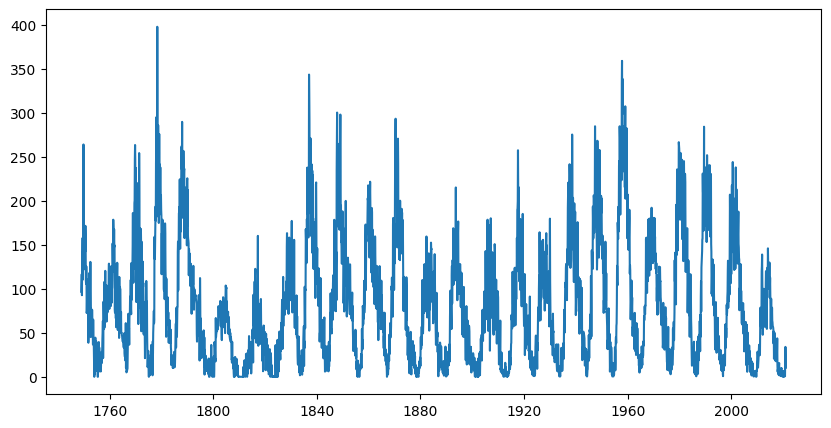

In [7]:
plt.figure(figsize = (10,5))
plt.plot(sunspots['Date'], sunspots['Monthly Mean Total Sunspot Number'])

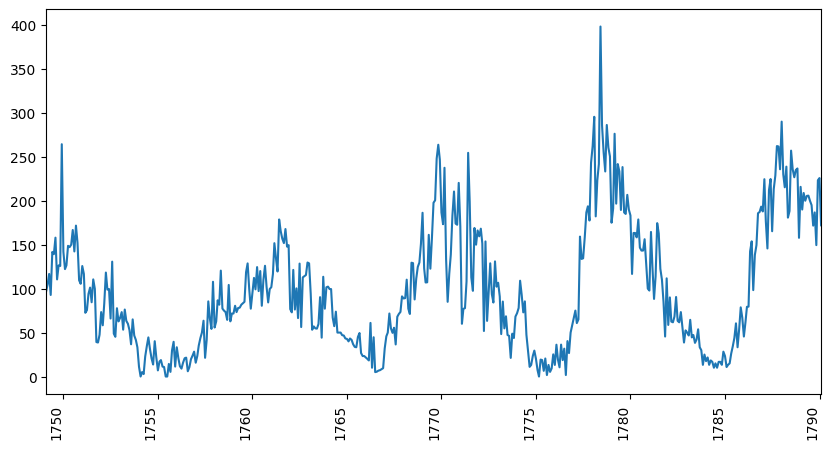

In [8]:
plt.figure(figsize = (10,5));
plt.plot(sunspots['Date'], sunspots['Monthly Mean Total Sunspot Number']);
plt.xlim(pd.Timestamp('1749-01-31'), pd.Timestamp('1790-01-31'));
plt.xticks(rotation=90, ha='right');


We can see that the cycles are ~11 years long.

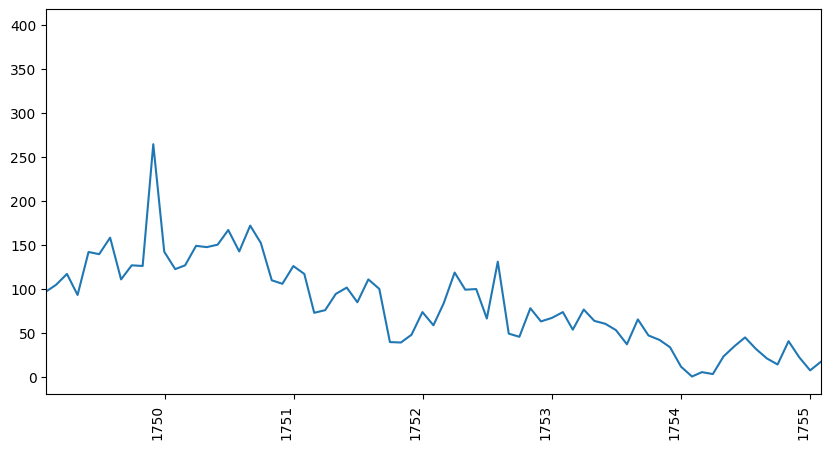

In [9]:
plt.figure(figsize = (10,5));
plt.plot(sunspots['Date'], sunspots['Monthly Mean Total Sunspot Number']);
plt.xlim(pd.Timestamp('1749-01-31'), pd.Timestamp('1755-01-31'));
plt.xticks(rotation=90, ha='right');

Data that are truly periodic have a behavior that repeats exactly over a fixed time frame.

In [10]:
airpass = pd.read_csv('AirPassengers.csv')
airpass.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Month        144 non-null    str  
 1   #Passengers  144 non-null    int64
dtypes: int64(1), str(1)
memory usage: 2.4 KB


In [11]:
airpass

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


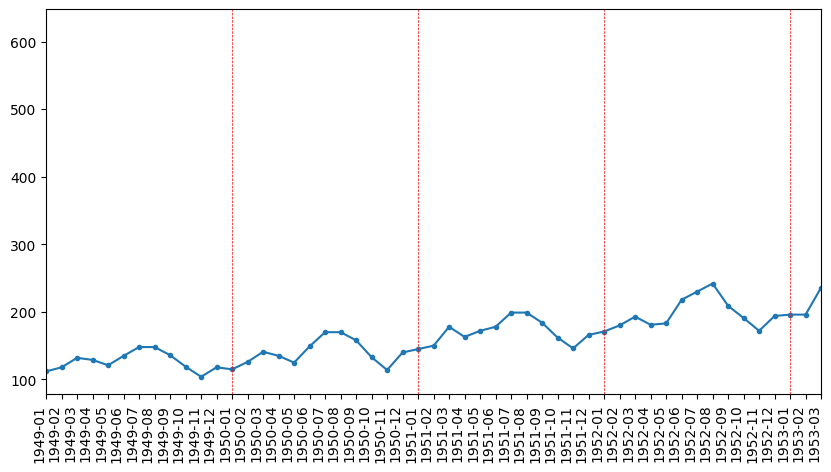

In [12]:
plt.figure(figsize = (10,5))
plt.plot(airpass['Month'], airpass['#Passengers'], marker = '.')
plt.xlim(left = airpass['Month'][0], right = airpass['Month'][50])
plt.xticks(rotation=90, ha='right')

plt.axvline(airpass['Month'][12], color = 'red', ls = '--', lw = 0.5)
plt.axvline(airpass['Month'][24], color = 'red', ls = '--', lw = 0.5)
plt.axvline(airpass['Month'][36], color = 'red', ls = '--', lw = 0.5)
plt.axvline(airpass['Month'][48], color = 'red', ls = '--', lw = 0.5)

The cyclic behavior of the air passenger data is repeated on an annual basis.

## Trends

A trend is a tendency for data to increase (or decrease) steadily over time.

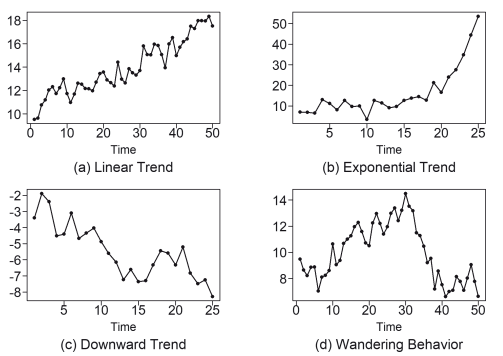

Source: Time Series for Data Science - Analysis and Forecasting. Wayne A. Woodward, Bivin P.Sadler, Stephen D. Robertson

#### Task: Identify and describe the patterns and the trend of the bicycle_rent dataset.

# Date as an index

https://www.macrotrends.net/stocks/charts/BRK.A/berkshire-hathaway/stock-price-history

In [13]:
brk = pd.read_csv('MacroTrends_Data_Download_BRK.A.csv', skiprows = 14)

In [14]:
brk

,date,open,high,low,close,volume
0,1980-03-17,290.0,310.0,290.0,290.0,100
1,1980-03-19,290.0,310.0,290.0,290.0,200
2,1980-03-24,270.0,290.0,270.0,270.0,100
3,1980-03-31,260.0,280.0,260.0,260.0,100
4,1980-04-01,260.0,280.0,260.0,260.0,300
...,...,...,...,...,...,...
11036,2025-09-08,749543.0,749700.0,739200.0,740099.0,714
11037,2025-09-09,739881.0,745000.0,737226.0,738781.0,260
11038,2025-09-10,736300.0,738064.0,730000.0,737994.0,607
11039,2025-09-11,735356.0,745640.0,732522.0,745001.0,366


In [15]:
brk.info()

<class 'pandas.DataFrame'>
RangeIndex: 11041 entries, 0 to 11040
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    11041 non-null  str    
 1   open    11041 non-null  float64
 2   high    11041 non-null  float64
 3   low     11041 non-null  float64
 4   close   11041 non-null  float64
 5   volume  11041 non-null  int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 517.7 KB


# Date formating 

https://docs.python.org/3/library/datetime.html#strftime-and-strptime-behavior

In [16]:
# Format refers to the current state of the date string
brk['date'] = pd.to_datetime(brk['date'], format ='%Y-%m-%d') #Task formating


In [17]:
brk.info()

<class 'pandas.DataFrame'>
RangeIndex: 11041 entries, 0 to 11040
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    11041 non-null  datetime64[us]
 1   open    11041 non-null  float64       
 2   high    11041 non-null  float64       
 3   low     11041 non-null  float64       
 4   close   11041 non-null  float64       
 5   volume  11041 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 517.7 KB


In [18]:
brk = brk.set_index('date') # Important step -> Improve navigation of of dataset, ensures date is chronologically. 
brk.head(3)

,open,high,low,close,volume
date,,,,,
1980-03-17,290.0,310.0,290.0,290.0,100
1980-03-19,290.0,310.0,290.0,290.0,200
1980-03-24,270.0,290.0,270.0,270.0,100


In [19]:
brk['2008-09-10':'2008-09-20']

,open,high,low,close,volume
date,,,,,
2008-09-10,118500.0,118500.0,117000.0,117000.0,596
2008-09-11,116200.0,117500.0,115500.0,117500.0,520
2008-09-12,116700.0,119500.0,116310.0,119500.0,865
2008-09-15,117000.0,123100.0,115500.0,119900.0,2232
2008-09-16,119000.0,125010.0,118300.0,125000.0,2562
2008-09-17,125000.0,125600.0,122900.0,124800.0,1800
2008-09-18,126000.0,128900.0,121310.0,128010.0,2765
2008-09-19,130000.0,147000.0,127901.0,147000.0,4228


# Filling data gaps

In [20]:
brk.head(10)

,open,high,low,close,volume
date,,,,,
1980-03-17,290.0,310.0,290.0,290.0,100
1980-03-19,290.0,310.0,290.0,290.0,200
1980-03-24,270.0,290.0,270.0,270.0,100
1980-03-31,260.0,280.0,260.0,260.0,100
1980-04-01,260.0,280.0,260.0,260.0,300
1980-04-03,260.0,280.0,260.0,260.0,100
1980-04-07,265.0,285.0,265.0,265.0,100
1980-04-08,265.0,285.0,265.0,265.0,100
1980-04-09,265.0,285.0,265.0,265.0,100


In [21]:
brk[4:6].resample('1d').asfreq()


# resample() - Convenience method for frequency conversion and resampling of time series. 
# asfreq() - can be used for changing the DatetimeIndex to have a different frequency
# while keeping the same values at the current index

C:\Users\keiron.jones.TETRAD\AppData\Local\Temp\ipykernel_13212\1549110325.py:1: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  brk[4:6].resample('1d').asfreq()


,open,high,low,close,volume
date,,,,,
1980-04-01,260.0,280.0,260.0,260.0,300.0
1980-04-02,NaN,NaN,NaN,NaN,NaN
1980-04-03,260.0,280.0,260.0,260.0,100.0


https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.resample.html

In [22]:
brk_resampled = brk.resample('1d').asfreq()
brk_resampled

C:\Users\keiron.jones.TETRAD\AppData\Local\Temp\ipykernel_13212\2194645548.py:1: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  brk_resampled = brk.resample('1d').asfreq()


,open,high,low,close,volume
date,,,,,
1980-03-17,290.0,310.0,290.0,290.0,100.0
1980-03-18,NaN,NaN,NaN,NaN,NaN
1980-03-19,290.0,310.0,290.0,290.0,200.0
1980-03-20,NaN,NaN,NaN,NaN,NaN
1980-03-21,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
2025-09-08,749543.0,749700.0,739200.0,740099.0,714.0
2025-09-09,739881.0,745000.0,737226.0,738781.0,260.0
2025-09-10,736300.0,738064.0,730000.0,737994.0,607.0


In [23]:
brk_resampled.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 16616 entries, 1980-03-17 to 2025-09-12
Freq: D
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    11041 non-null  float64
 1   high    11041 non-null  float64
 2   low     11041 non-null  float64
 3   close   11041 non-null  float64
 4   volume  11041 non-null  float64
dtypes: float64(5)
memory usage: 778.9 KB


In [24]:
brk_resampled.isnull().sum()

open      5575
high      5575
low       5575
close     5575
volume    5575
dtype: int64

<Axes: xlabel='date'>

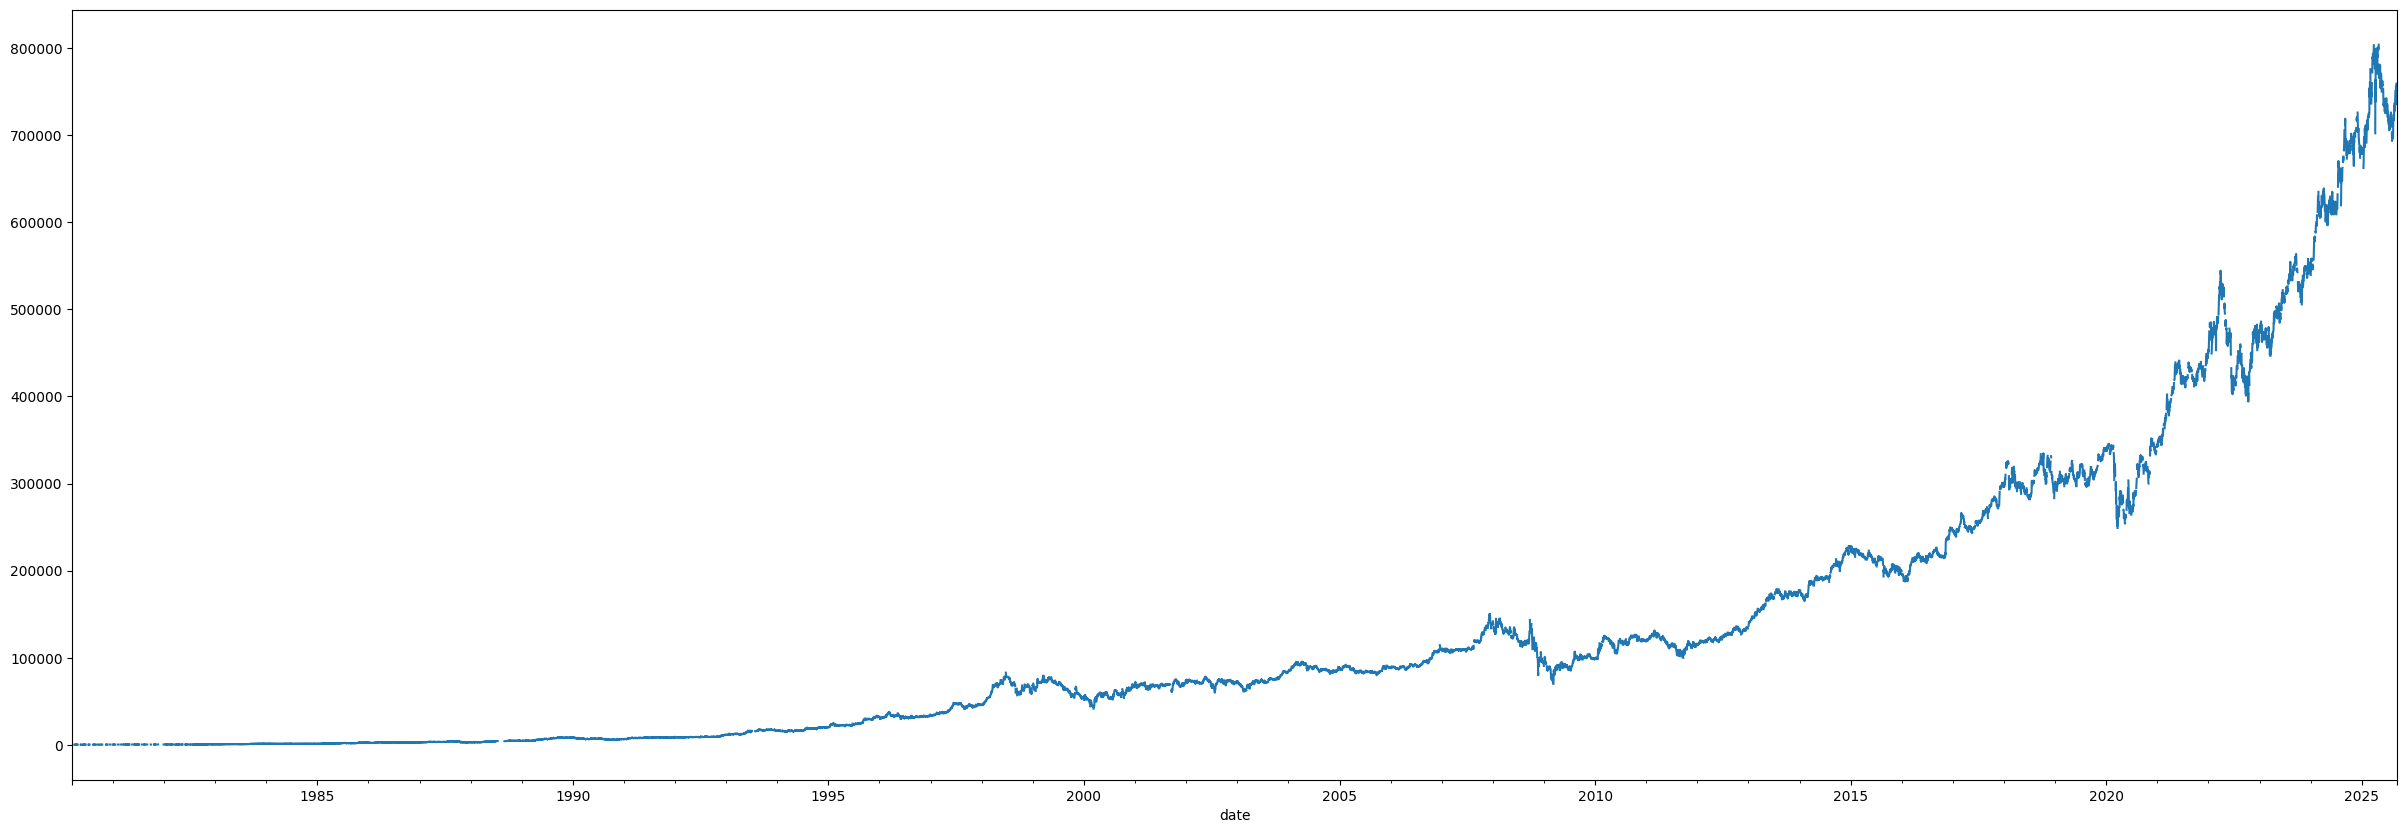

In [25]:
brk_resampled['open'].plot(figsize = (30, 10))

In [26]:
brk[4:6]

,open,high,low,close,volume
date,,,,,
1980-04-01,260.0,280.0,260.0,260.0,300
1980-04-03,260.0,280.0,260.0,260.0,100


In [27]:
brk[4:6].resample('1d').bfill()

C:\Users\keiron.jones.TETRAD\AppData\Local\Temp\ipykernel_13212\1203499898.py:1: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  brk[4:6].resample('1d').bfill()


,open,high,low,close,volume
date,,,,,
1980-04-01,260.0,280.0,260.0,260.0,300
1980-04-02,260.0,280.0,260.0,260.0,100
1980-04-03,260.0,280.0,260.0,260.0,100


In [28]:
brk[4:6].resample('1d').ffill()

C:\Users\keiron.jones.TETRAD\AppData\Local\Temp\ipykernel_13212\2267949661.py:1: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  brk[4:6].resample('1d').ffill()


,open,high,low,close,volume
date,,,,,
1980-04-01,260.0,280.0,260.0,260.0,300
1980-04-02,260.0,280.0,260.0,260.0,300
1980-04-03,260.0,280.0,260.0,260.0,100


In [29]:
brk_resampled.tail(10)

,open,high,low,close,volume
date,,,,,
2025-09-03,750876.0,753194.0,745000.0,751808.0,307.0
2025-09-04,753022.0,760837.0,750595.0,759798.0,313.0
2025-09-05,759046.0,759697.0,746630.0,750104.0,250.0
2025-09-06,NaN,NaN,NaN,NaN,NaN
2025-09-07,NaN,NaN,NaN,NaN,NaN
2025-09-08,749543.0,749700.0,739200.0,740099.0,714.0
2025-09-09,739881.0,745000.0,737226.0,738781.0,260.0
2025-09-10,736300.0,738064.0,730000.0,737994.0,607.0
2025-09-11,735356.0,745640.0,732522.0,745001.0,366.0


- .bfill() - The backward fill will replace NaN values that appeared in the resampled data with the next value in the original sequence. Missing values that existed in the original data will not be modified.
- .ffill() - Forward fill the values.

In [30]:
brk_resampled_bfill = brk_resampled.ffill()
brk_resampled_bfill.tail(10)

,open,high,low,close,volume
date,,,,,
2025-09-03,750876.0,753194.0,745000.0,751808.0,307.0
2025-09-04,753022.0,760837.0,750595.0,759798.0,313.0
2025-09-05,759046.0,759697.0,746630.0,750104.0,250.0
2025-09-06,759046.0,759697.0,746630.0,750104.0,250.0
2025-09-07,759046.0,759697.0,746630.0,750104.0,250.0
2025-09-08,749543.0,749700.0,739200.0,740099.0,714.0
2025-09-09,739881.0,745000.0,737226.0,738781.0,260.0
2025-09-10,736300.0,738064.0,730000.0,737994.0,607.0
2025-09-11,735356.0,745640.0,732522.0,745001.0,366.0


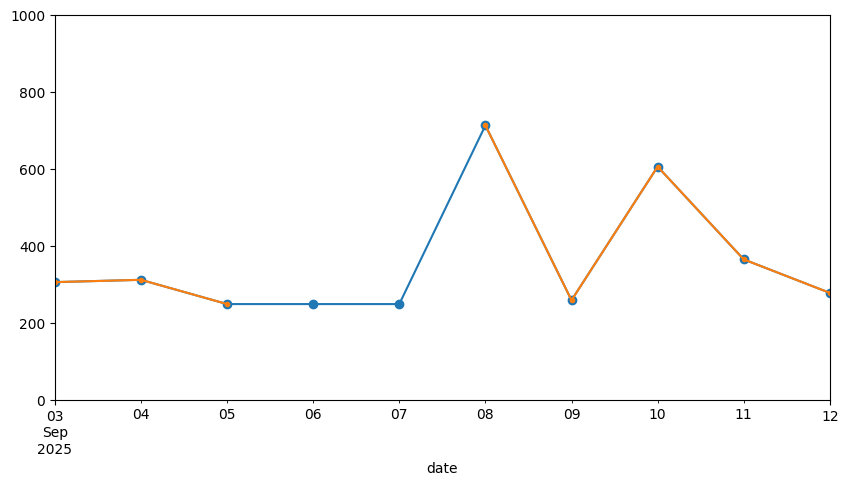

In [31]:
brk_resampled_bfill['volume'].plot(figsize = (10, 5), marker='o')
brk_resampled['volume'].plot(figsize = (10, 5), marker='.')

plt.xlim(pd.Timestamp('2025-09-03'), pd.Timestamp('2025-09-12'));
plt.ylim([0, 1000]);




Fill the missing values: 
1. with the nearest value
2. with the mean, median, most frequent value
3. with the predictions of a regressor model
4. by using the interpolation technique

For example one the interpolation methods available is linear interpolation. Linear interpolation can be used to input missing data by drawing a straight line between the two points surrounding the missing value(in time series: it looks at prior past value and the next future value to draw a line between them). 
A polynomial interpolation will attempt to draw a curved line between the two points.

Source: Time Series Analysis with Python Cookbook, Tarek A. Atwan

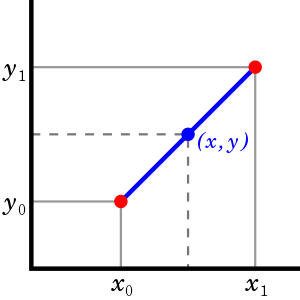

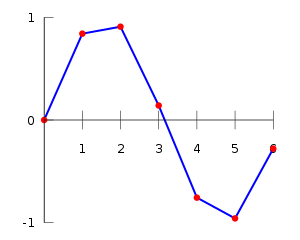

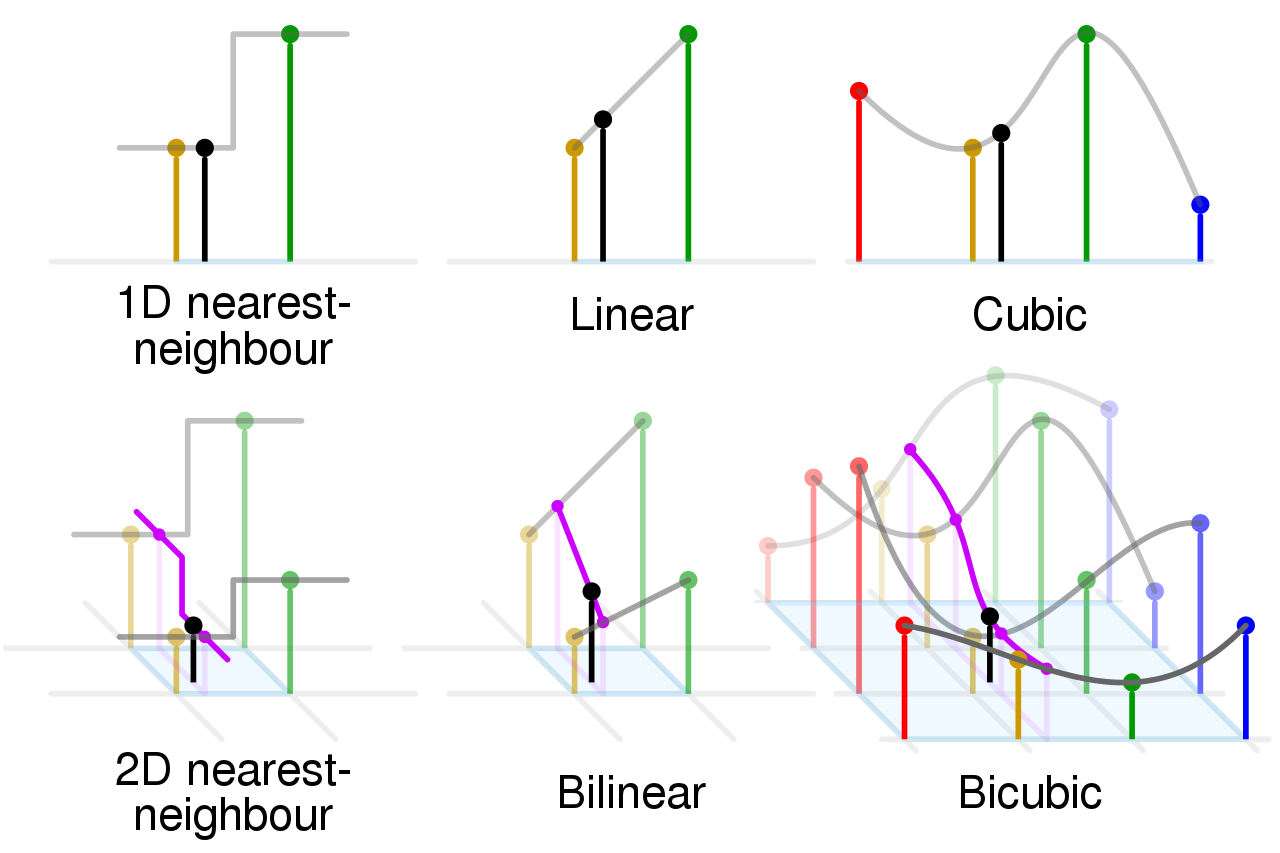

In [32]:
brk_resampled.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 16616 entries, 1980-03-17 to 2025-09-12
Freq: D
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    11041 non-null  float64
 1   high    11041 non-null  float64
 2   low     11041 non-null  float64
 3   close   11041 non-null  float64
 4   volume  11041 non-null  float64
dtypes: float64(5)
memory usage: 778.9 KB


In [33]:
brk_resampled_volume_linear = brk_resampled['volume'].interpolate('linear')

# 'quadratic', 'nearest', 'cubic'

In [34]:
brk_resampled.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 16616 entries, 1980-03-17 to 2025-09-12
Freq: D
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    11041 non-null  float64
 1   high    11041 non-null  float64
 2   low     11041 non-null  float64
 3   close   11041 non-null  float64
 4   volume  11041 non-null  float64
dtypes: float64(5)
memory usage: 778.9 KB


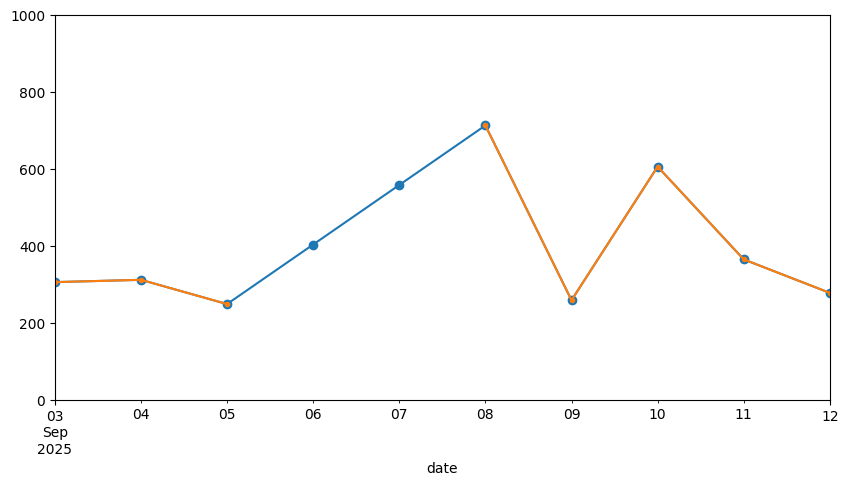

In [35]:
brk_resampled_volume_linear.plot(figsize = (10, 5), marker='o')
brk_resampled['volume'].plot(figsize = (10, 5), marker='.')

plt.xlim(pd.Timestamp('2025-09-03'), pd.Timestamp('2025-09-12'));
plt.ylim([0, 1000]);

# Task 1

# Resampling

In [36]:
brk_resampled[14:16]

,open,high,low,close,volume
date,,,,,
1980-03-31,260.0,280.0,260.0,260.0,100.0
1980-04-01,260.0,280.0,260.0,260.0,300.0


In [37]:
brk_resampled[14:16].resample('6h').asfreq()

,open,high,low,close,volume
date,,,,,
1980-03-31 00:00:00,260.0,280.0,260.0,260.0,100.0
1980-03-31 06:00:00,NaN,NaN,NaN,NaN,NaN
1980-03-31 12:00:00,NaN,NaN,NaN,NaN,NaN
1980-03-31 18:00:00,NaN,NaN,NaN,NaN,NaN
1980-04-01 00:00:00,260.0,280.0,260.0,260.0,300.0


# Unsampling

In [38]:
brk_resampled[:10]

,open,high,low,close,volume
date,,,,,
1980-03-17,290.0,310.0,290.0,290.0,100.0
1980-03-18,NaN,NaN,NaN,NaN,NaN
1980-03-19,290.0,310.0,290.0,290.0,200.0
1980-03-20,NaN,NaN,NaN,NaN,NaN
1980-03-21,NaN,NaN,NaN,NaN,NaN
1980-03-22,NaN,NaN,NaN,NaN,NaN
1980-03-23,NaN,NaN,NaN,NaN,NaN
1980-03-24,270.0,290.0,270.0,270.0,100.0
1980-03-25,NaN,NaN,NaN,NaN,NaN


Downsample the series into 1-week bins and sum the values of the timestamps that fall into a bin.

In [39]:
brk_resampled['volume'].resample('1W').sum()

date
1980-03-23     300.0
1980-03-30     100.0
1980-04-06     500.0
1980-04-13    1200.0
1980-04-20     700.0
               ...  
2025-08-17    1838.0
2025-08-24    1531.0
2025-08-31    1613.0
2025-09-07    1239.0
2025-09-14    2226.0
Freq: W-SUN, Name: volume, Length: 2374, dtype: float64

# Task 2

# EDA

In [40]:
brk_resampled_linear = brk_resampled.interpolate('linear')

In [41]:
brk_resampled_linear

,open,high,low,close,volume
date,,,,,
1980-03-17,290.0,310.0,290.0,290.0,100.0
1980-03-18,290.0,310.0,290.0,290.0,150.0
1980-03-19,290.0,310.0,290.0,290.0,200.0
1980-03-20,286.0,306.0,286.0,286.0,180.0
1980-03-21,282.0,302.0,282.0,282.0,160.0
...,...,...,...,...,...
2025-09-08,749543.0,749700.0,739200.0,740099.0,714.0
2025-09-09,739881.0,745000.0,737226.0,738781.0,260.0
2025-09-10,736300.0,738064.0,730000.0,737994.0,607.0


In [42]:
series = brk_resampled_linear['open']

In [43]:
series.describe()

count     16616.000000
mean     133177.539537
std      167911.997751
min         245.000000
25%        8500.000000
50%       73800.000000
75%      189112.500000
max      803783.000000
Name: open, dtype: float64

Things to pay attention to:

- The std and the first and third quantiles suggest that the data is widely spread around the mean.
- The mean and median(50%) are not equal. The mean is higher.
- There are 16616 data points.

## Plotting

### Line plot

<Axes: xlabel='date'>

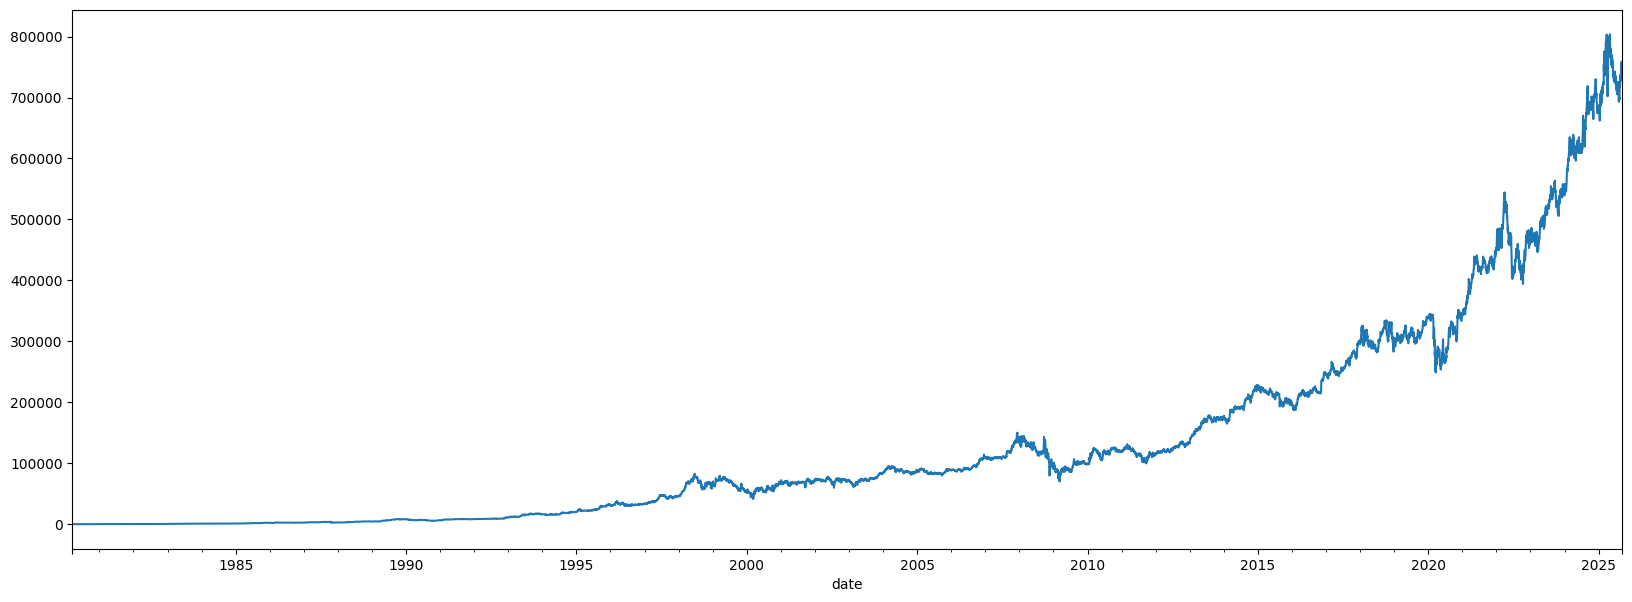

In [44]:
brk_resampled_linear['open'].plot(figsize = (20, 7))

<Axes: xlabel='date'>

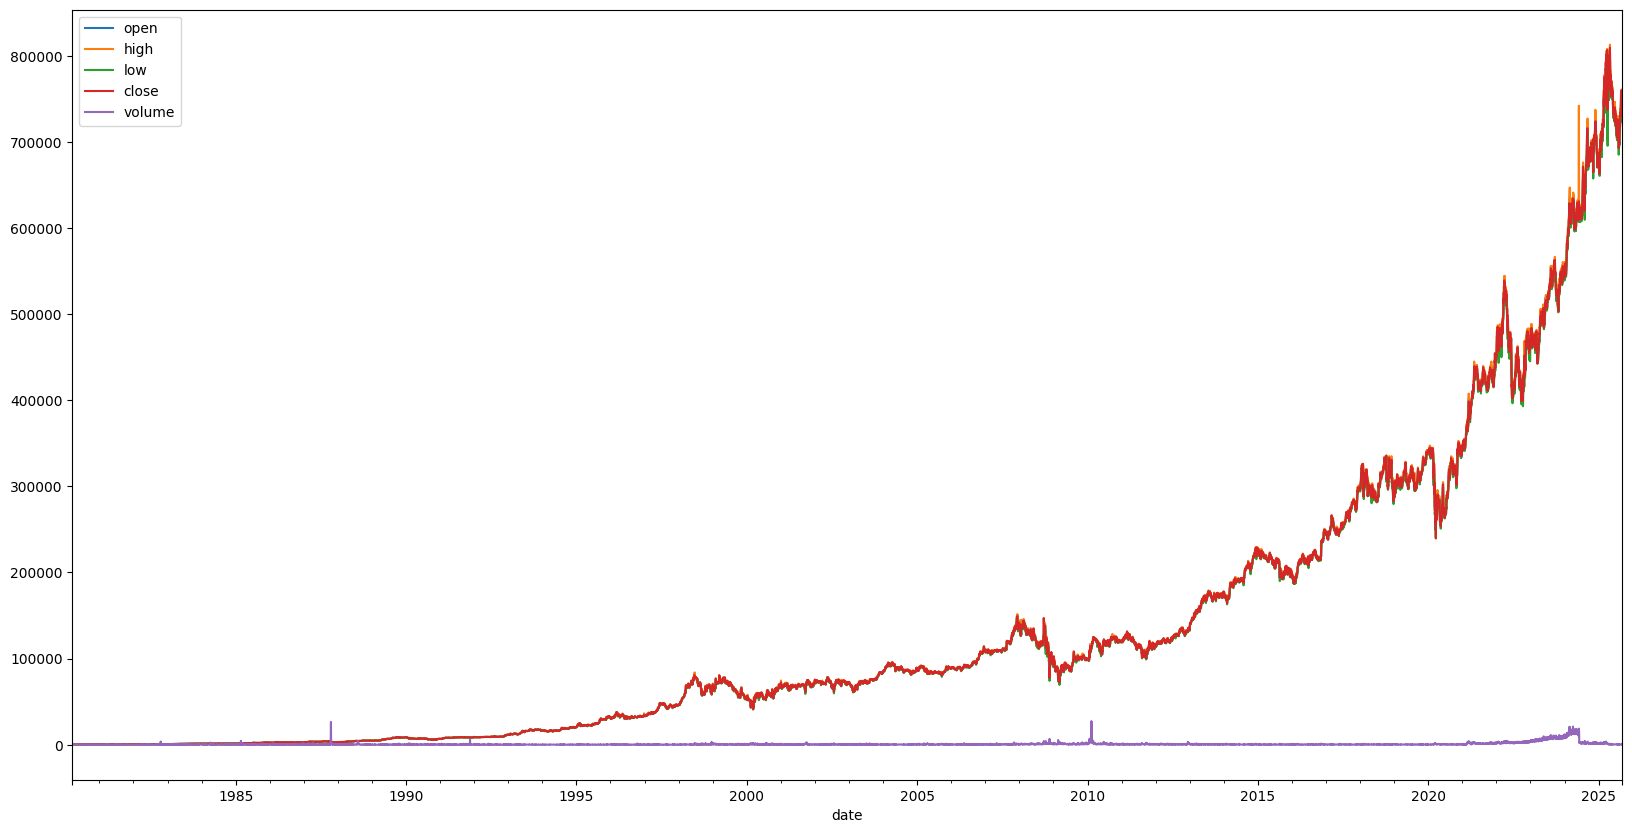

In [45]:
brk_resampled_linear.plot(figsize = (20, 10))

array([<Axes: xlabel='date'>, <Axes: xlabel='date'>,
       <Axes: xlabel='date'>, <Axes: xlabel='date'>,
       <Axes: xlabel='date'>], dtype=object)

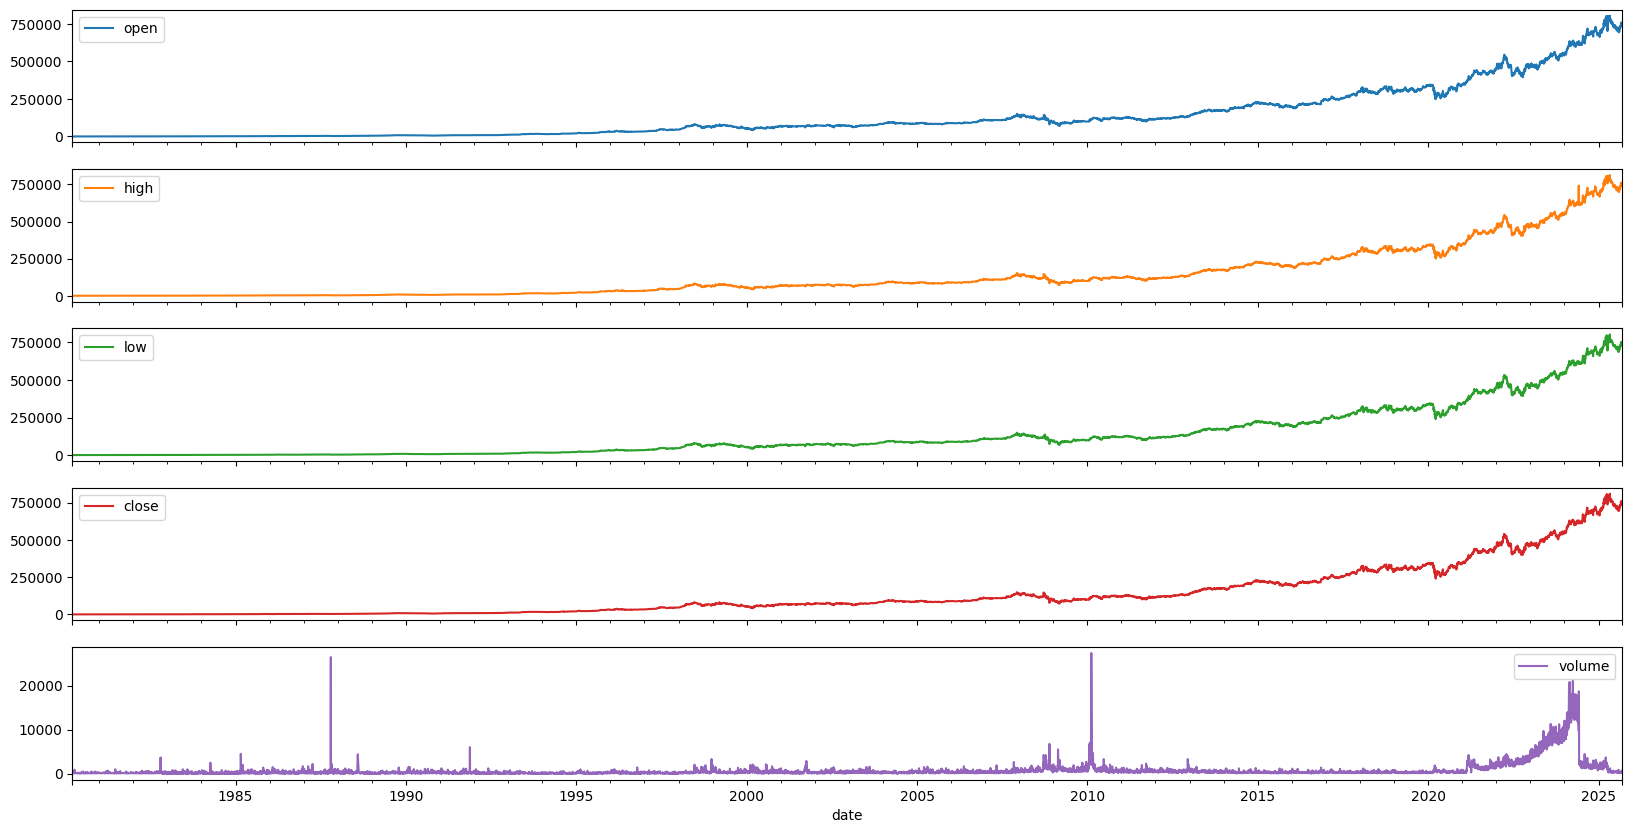

In [46]:
plt.style.use('default')

brk_resampled_linear.plot(figsize = (20, 10), subplots = True)

# styles: 'fivethirtyeight', 'dark_background', 'seaborn-dark', 'tableau-colorblind10', 'default'

more styles here: https://matplotlib.org/stable/gallery/style_sheets/style_sheets_reference.html

In [47]:
brk_resampled_linear.corr()

,open,high,low,close,volume
open,1.000000,0.999942,0.999961,0.999930,0.533013
high,0.999942,1.000000,0.999920,0.999945,0.533805
low,0.999961,0.999920,1.000000,0.999964,0.532366
close,0.999930,0.999945,0.999964,1.000000,0.532803
volume,0.533013,0.533805,0.532366,0.532803,1.000000


### Dot plot

<Axes: xlabel='date'>

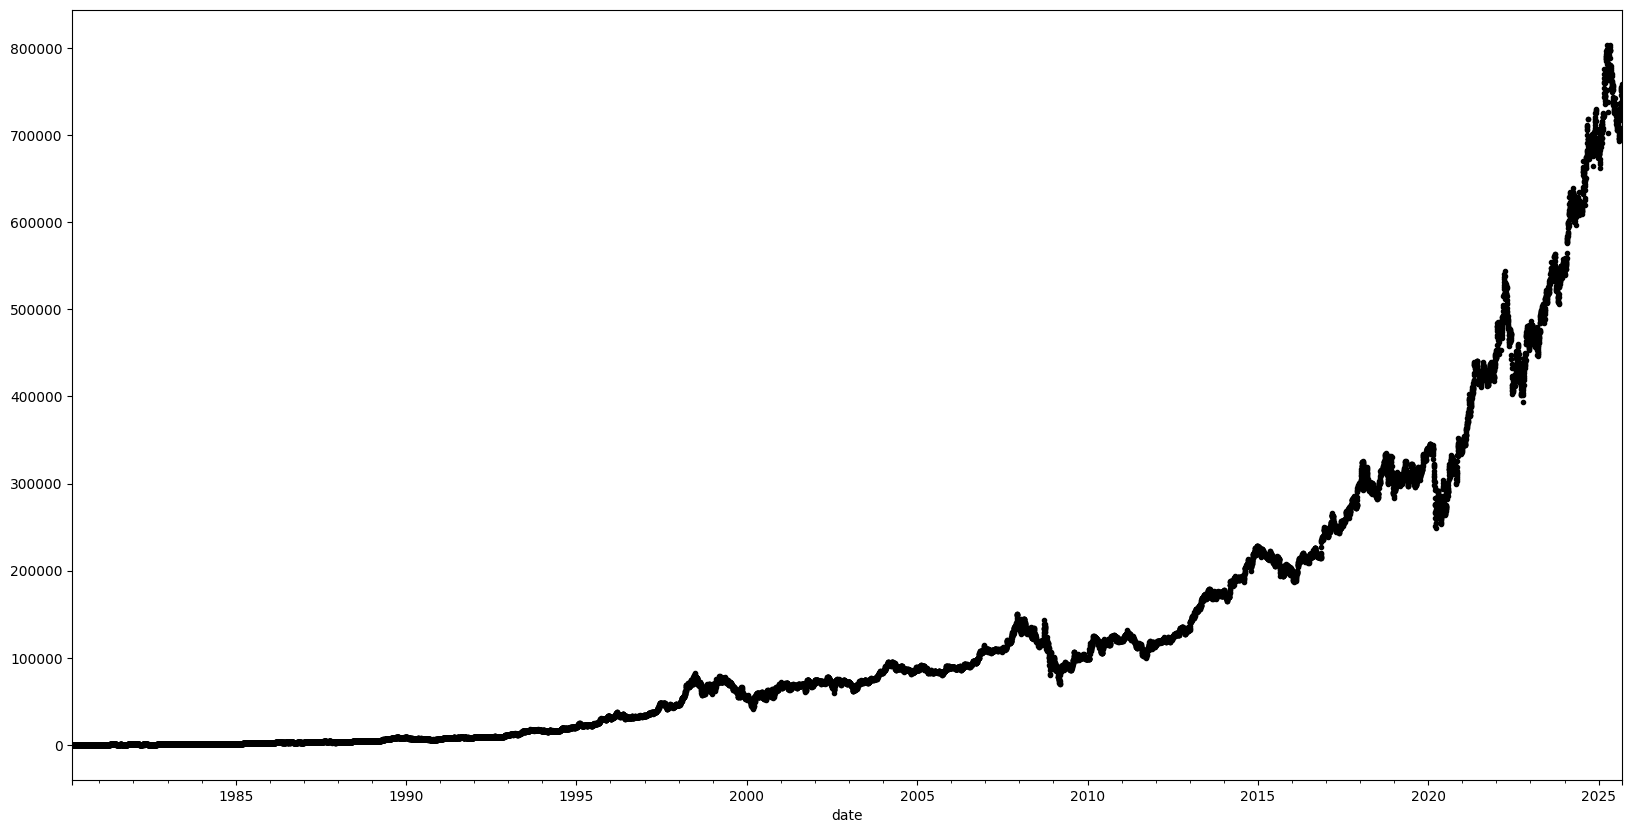

In [48]:
brk_resampled_linear['open'].plot(style = 'k.', figsize = (20, 10))

### Group by years

In [49]:
brk_week= brk_resampled_linear.resample('1W').mean()

In [50]:
groups = brk_week.groupby(pd.Grouper(freq = 'YE'))
groups

In [51]:
years = pd.DataFrame()

In [52]:
for name, group in groups:
    print(name)
    print(group)
    print('----------------')
    
    if len(group['open'].values) == 52:
        years[name.year] = group['open'].values
 

1980-12-31 00:00:00
                  open        high         low       close      volume
date                                                                  
1980-03-23  284.285714  304.285714  284.285714  284.285714  150.000000
1980-03-30  265.714286  285.714286  265.714286  265.714286  100.000000
1980-04-06  261.071429  281.071429  261.071429  261.071429  142.857143
1980-04-13  261.071429  281.071429  261.071429  261.071429  407.142857
1980-04-20  253.571429  273.571429  253.571429  253.571429  178.571429
1980-04-27  272.564935  292.564935  272.564935  272.564935  150.649351
1980-05-04  281.363636  301.363636  281.363636  281.363636  163.636364
1980-05-11  292.500000  312.500000  292.500000  292.500000  162.500000
1980-05-18  307.857143  327.857143  307.857143  307.857143  133.928571
1980-05-25  314.285714  334.285714  314.285714  314.285714  139.285714
1980-06-01  318.214286  338.214286  318.214286  318.214286  114.285714
1980-06-08  310.000000  330.000000  310.000000  310.00000

In [53]:
years.head()

,1981,1982,1983,1985,1986,1987,1988,1990,1991,1992,...,2013,2014,2015,2016,2018,2019,2020,2021,2022,2024
0,425.625000,560.000000,772.857143,1276.428571,2455.714286,2857.500000,3035.714286,8633.928571,6758.928571,8901.785714,...,138104.571429,176952.000000,226827.285714,198824.285714,299428.571429,298847.142857,339002.000000,344863.785714,449965.714286,550820.857143
1,426.875000,552.500000,778.571429,1297.142857,2447.857143,2984.285714,3072.142857,8332.857143,6730.000000,8803.571429,...,141261.000000,174229.714286,224832.000000,195154.285714,308049.857143,294628.571429,340641.714286,347389.285714,469038.857143,556434.535714
2,425.000000,540.357143,784.285714,1305.714286,2403.571429,3051.428571,3068.571429,8107.142857,6705.000000,8735.714286,...,143075.821429,172825.142857,222725.928571,191387.678571,320098.571429,298017.928571,342900.857143,350356.392857,481532.500000,550238.392857
3,428.214286,516.428571,769.642857,1332.142857,2297.857143,3065.714286,3108.571429,7686.428571,6896.428571,8642.857143,...,145497.678571,171265.428571,223611.642857,190330.250000,323518.714286,302983.071429,342406.571429,351567.107143,472154.785714,570518.714286
4,430.000000,507.142857,757.857143,1383.571429,2267.142857,3079.285714,3083.571429,7483.571429,7410.714286,8875.000000,...,146632.285714,168681.714286,220337.428571,190112.142857,321518.857143,307125.714286,336932.857143,346310.571429,461470.285714,582374.000000


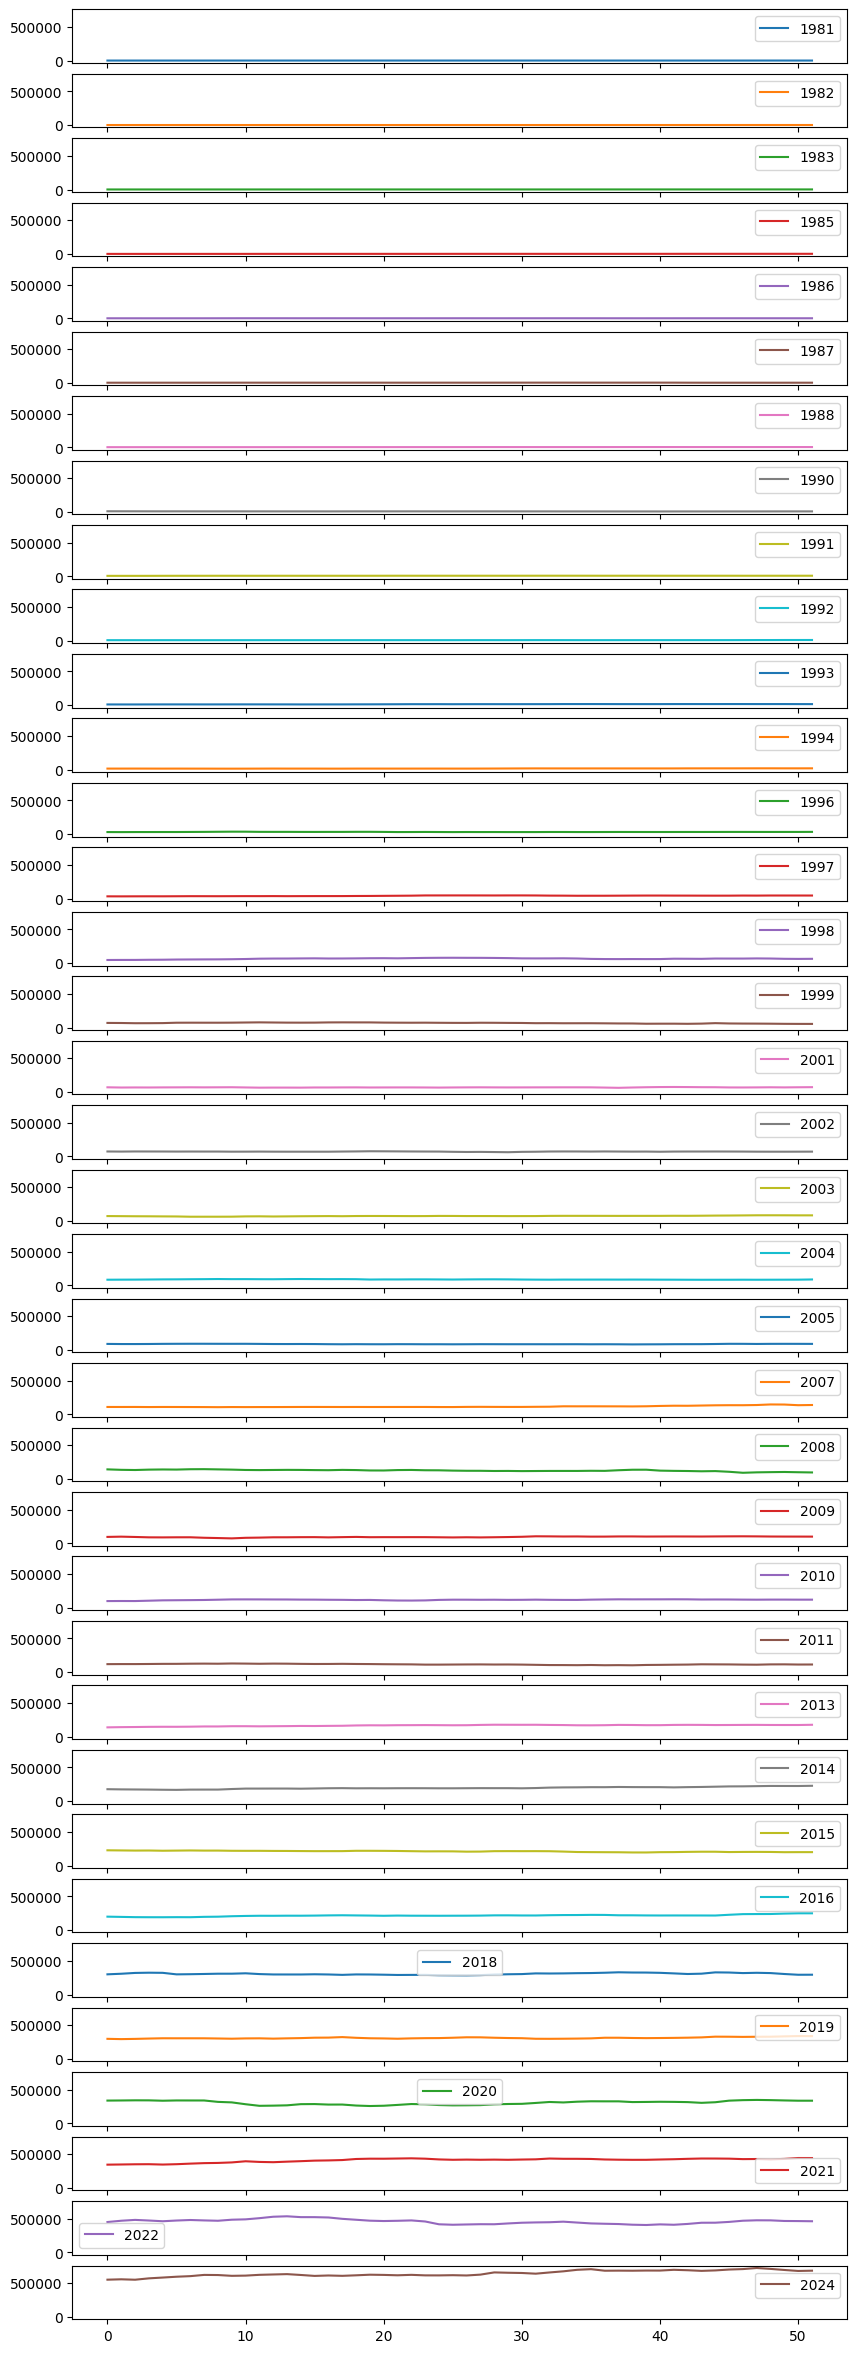

In [54]:
years.plot(subplots = True, legend = True, figsize = (10, 30), sharex = True, sharey = True);

### Box and Whisker plots

<Axes: >

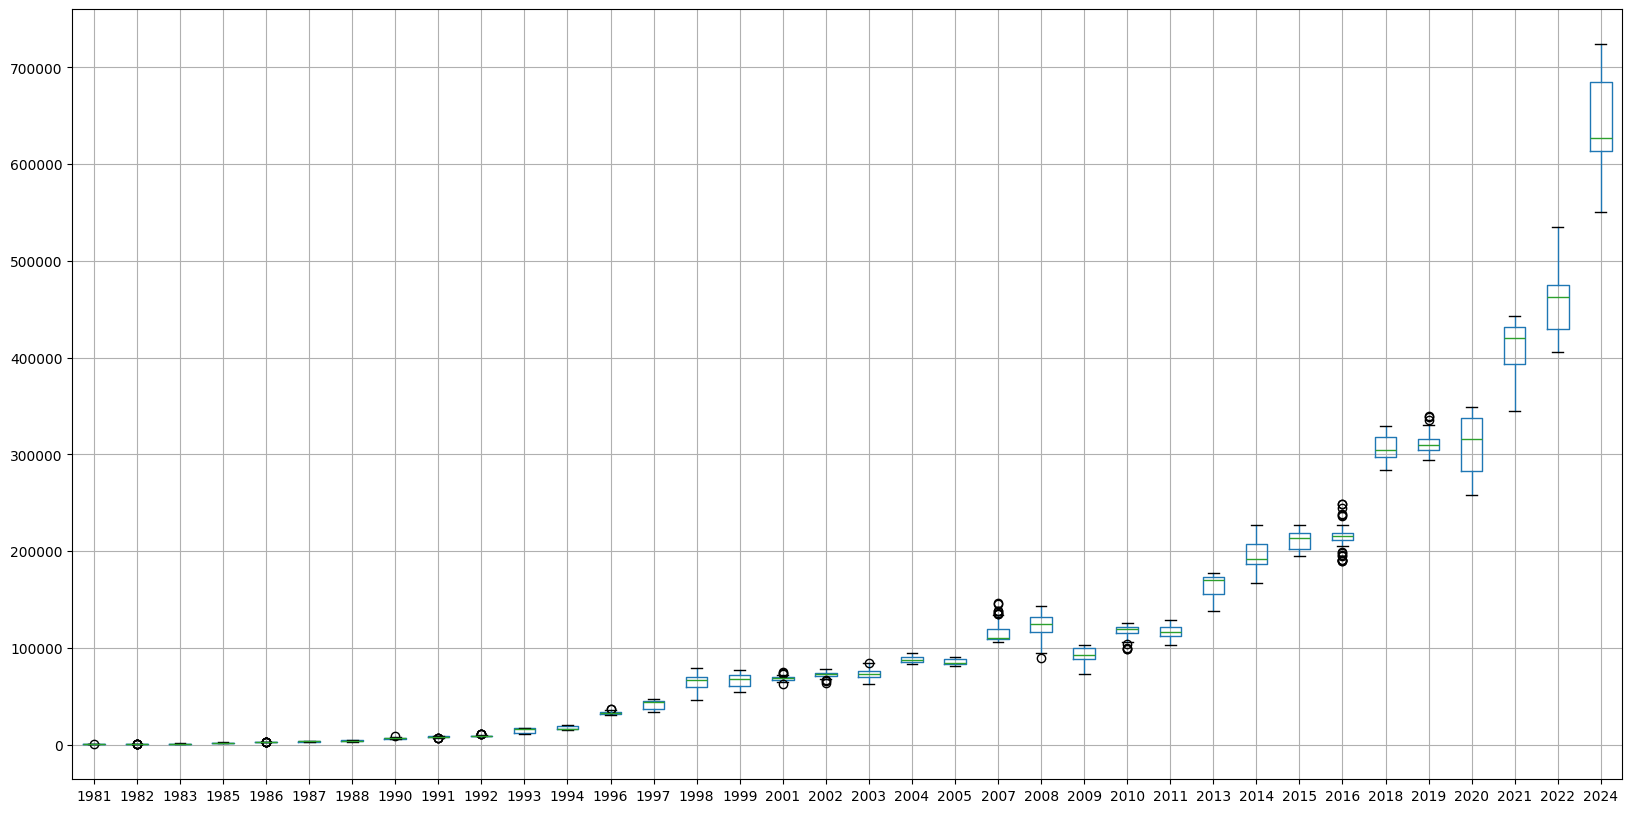

In [55]:
years.boxplot(figsize = (20, 10))

### Heat Maps

In [56]:
years_inverse = years.T

In [57]:
years_inverse.head()

,0,1,2,3,4,5,6,7,8,9,...,42,43,44,45,46,47,48,49,50,51
1981,425.625000,426.875000,425.000000,428.214286,430.000000,430.000000,427.571429,431.000000,467.142857,485.000000,...,481.530612,496.428571,515.000000,515.000000,530.714286,570.561224,586.224490,562.222222,559.206349,560.000000
1982,560.000000,552.500000,540.357143,516.428571,507.142857,513.928571,511.428571,510.714286,515.000000,505.714286,...,610.000000,615.306122,648.979592,681.428571,689.285714,690.000000,690.714286,702.500000,720.000000,757.142857
1983,772.857143,778.571429,784.285714,769.642857,757.857143,765.714286,768.571429,790.535714,819.107143,856.428571,...,1274.285714,1301.428571,1317.857143,1309.285714,1310.714286,1328.571429,1353.571429,1377.857143,1374.285714,1358.928571
1985,1276.428571,1297.142857,1305.714286,1332.142857,1383.571429,1455.000000,1485.714286,1490.000000,1490.000000,1490.000000,...,2545.000000,2591.428571,2523.571429,2608.571429,2619.285714,2619.642857,2615.714286,2609.285714,2560.000000,2505.000000
1986,2455.714286,2447.857143,2403.571429,2297.857143,2267.142857,2400.714286,2450.178571,2533.750000,2728.571429,2953.571429,...,2798.571429,2840.000000,2910.714286,2884.142857,2812.000000,2750.714286,2795.714286,2766.428571,2751.428571,2751.785714


<Axes: >

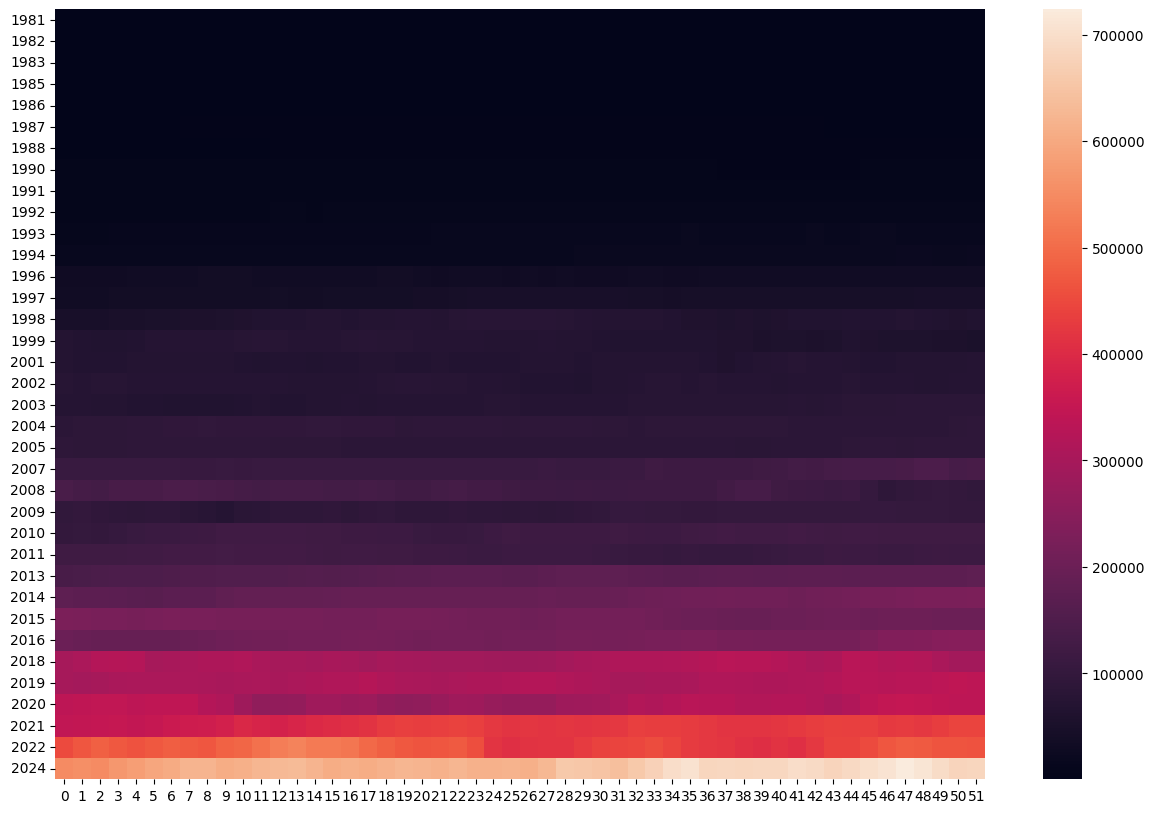

In [58]:
fig, ax = plt.subplots(figsize = (15, 10))
sns.heatmap(years_inverse)

### Histogram and density plots

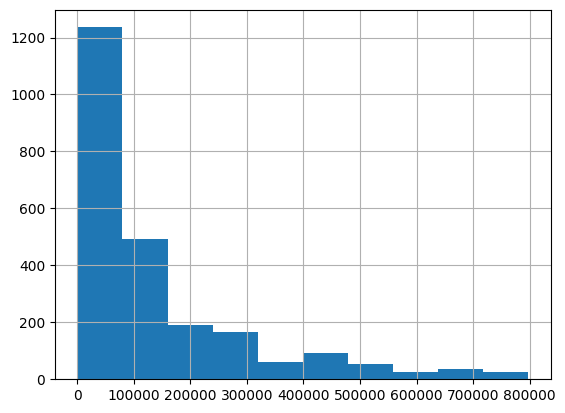

In [59]:
brk_week['open'].hist();

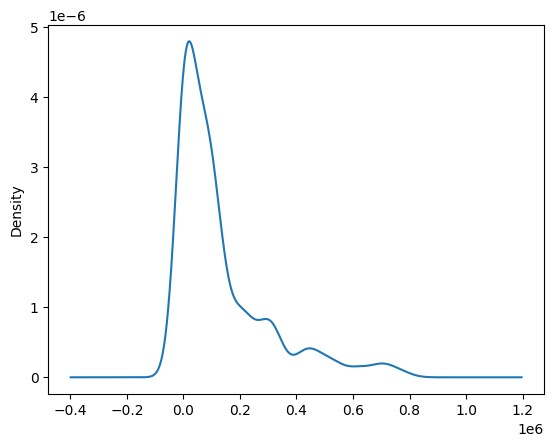

In [60]:
brk_week['open'].plot(kind = 'kde');

### Scatter plot

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

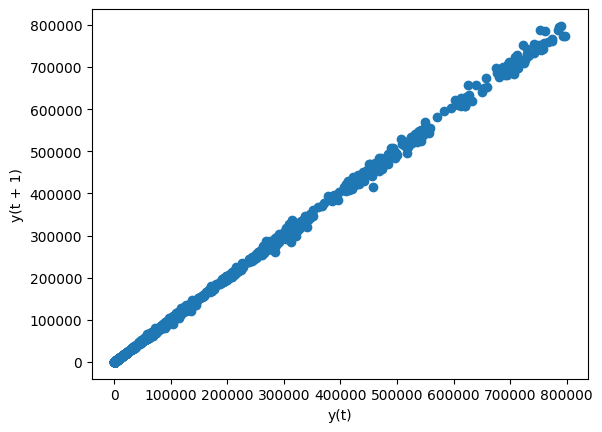

In [61]:
pd.plotting.lag_plot(brk_week['open'])

<Axes: xlabel='y(t)', ylabel='y(t + 2)'>

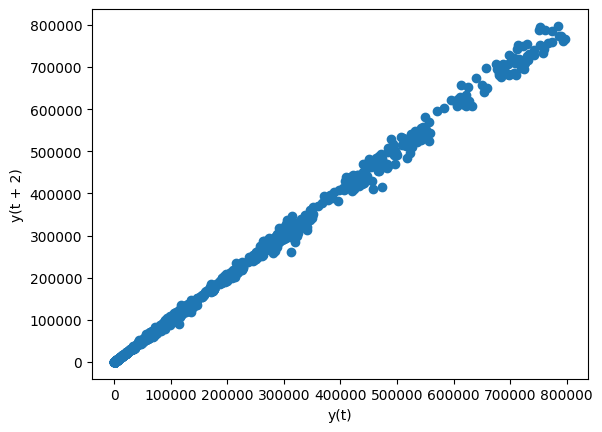

In [62]:
pd.plotting.lag_plot(brk_week['open'], lag = 2)

### Autocorrelation plot

In [63]:
from pandas.plotting import autocorrelation_plot

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

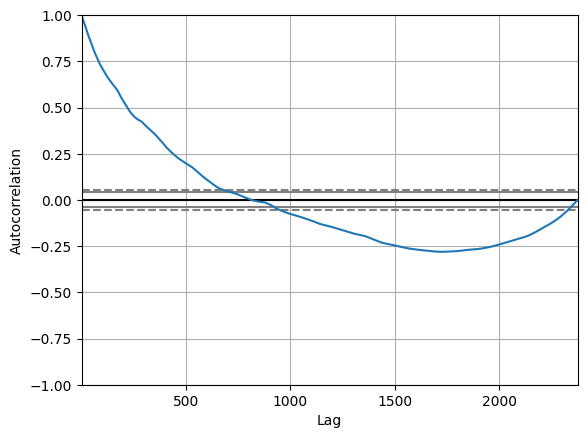

In [64]:
autocorrelation_plot(brk_week['open'])

# Task 3

## Decomposing time series data

There are three major components for any time series process: trend, seasonality, residual.

- Trend gives a sense of the long-term direction of the time series and can be either upward. downward or horisontal.
- Seasonality is repeated pattern over time. Example: Increasing of sales around Christmas each year.
- The Residuals are the remaining or unexplained data points once we extract trend and seasonality.


The decomposition of a time series is the process of extracting the three components. The modeling of the decomposed components can be either additive or multiplicative.

Based on the **additive model** we can reconstruct the original time series by adding all three components.

**y = Trend + Seasonality + Residual**

The additive model should be applied when the seasonal variations do not change over time.


Based on the **multiplicative model** we can reconstruct the time series data by multiplying the 3 components.

**y = Trend x Seasonality x Residual**

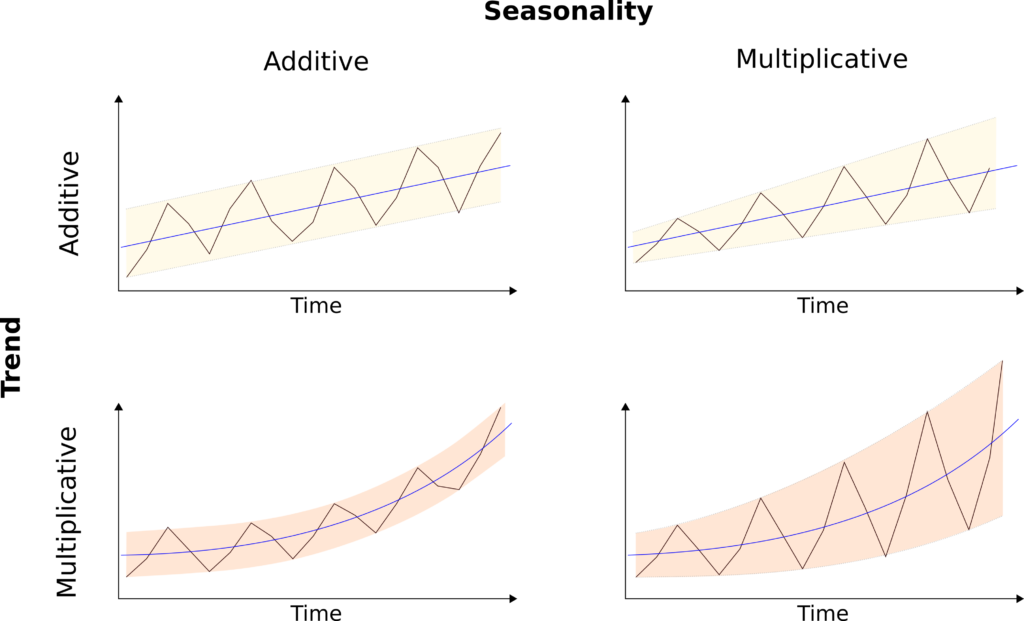

## Simulating time series data

In [65]:
def simulate_additive_ts(n_steps, period, trend_slope, seasonal_amplitude, noise_scale):
    """
    Simulates time series data using an Additive Model.
    Y(t) = Trend(t) + Seasonality(t) + Residual(t)

    Args:
        n_steps (int): Total number of time steps (length of the series).
        period (int): Number of steps in one seasonal cycle (e.g., 12 for monthly).
        trend_slope (float): Rate of linear trend growth.
        seasonal_amplitude (float): Magnitude of the seasonal component.
        noise_scale (float): Standard deviation of the random noise.

    Returns:
        np.array: The simulated time series data.
    """
    
    time = np.arange(n_steps)
    # 1. Trend Component (Linear --> ax + b)
    trend = trend_slope * time

    # 2. Seasonality Component (Sine wave)
    seasonality = seasonal_amplitude * np.sin(2 * np.pi * time / period)

    # 3. Residual/Noise Component (Normal distribution)
    np.random.seed(42) # for reproducibility
    residual = np.random.normal(loc=0.0, scale=noise_scale, size=n_steps)

    # Combine components: Additive Model
    time_series = trend + seasonality + residual
    return time_series, trend, seasonality, residual

In [66]:
time_series, trend, seasonality, residual = simulate_additive_ts(n_steps=100, period=12, trend_slope=0.5, seasonal_amplitude=10, noise_scale=2)

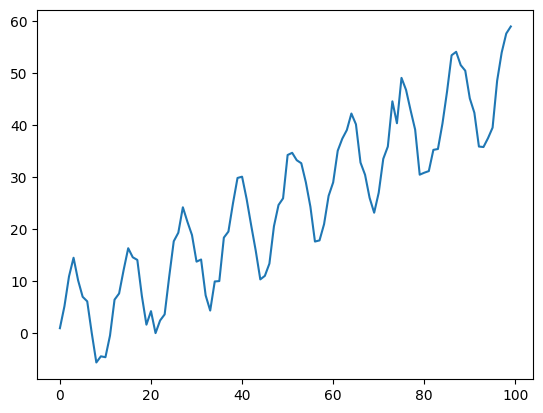

In [67]:
plt.plot(time_series)

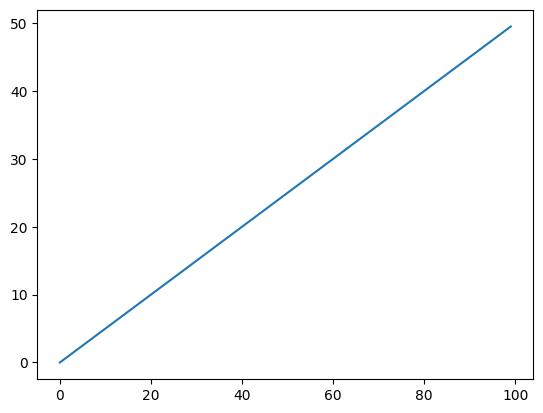

In [68]:
plt.plot(trend)

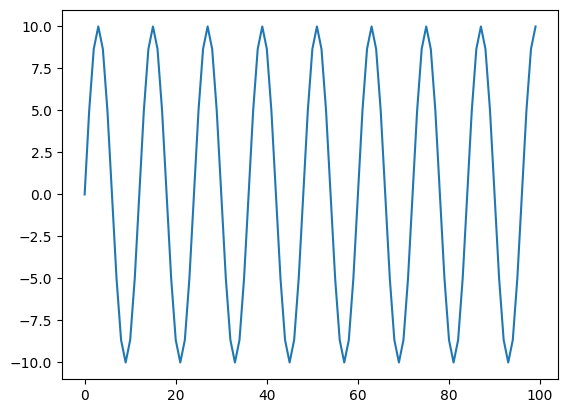

In [69]:
plt.plot(seasonality)

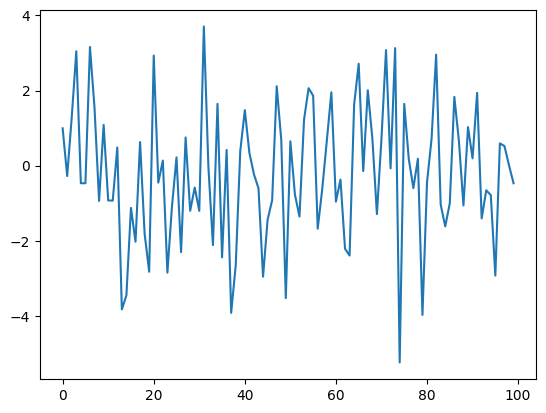

In [70]:
plt.plot(residual)

In [71]:
def simulate_multiplicative_ts(n_steps, period, trend_base, trend_growth_rate, seasonal_factors_range, noise_scale):
    """
    Simulates time series data using a Multiplicative Model.
    Y(t) = Trend(t) * Seasonality(t) * Residual(t)

    Args:
        n_steps (int): Total number of time steps (length of the series).
        period (int): Number of steps in one seasonal cycle.
        trend_base (float): Base value for the trend (e.g., the starting level).
        trend_growth_rate (float): Multiplicative rate of trend growth (e.g., 1.05 for 5% growth).
        seasonal_factors_range (float): Magnitude of seasonal factors (e.g., 0.1 for factors between 0.9 and 1.1).
        noise_scale (float): Standard deviation for the noise factor around 1.0.

    Returns:
        np.array: The simulated time series data.
    """
    time = np.arange(n_steps)

    # 1. Trend Component (Exponential)
    trend = trend_base * (trend_growth_rate ** (time / period))

    # 2. Seasonality Component (Factors around 1.0)
    # Seasonal factors will be between 1 - factor_range and 1 + factor_range
    seasonal_factors = 1 + seasonal_factors_range * np.sin(2 * np.pi * time / period)

    # 3. Residual/Noise Component (Factors around 1.0)
    np.random.seed(42) # for reproducibility
    # Noise is typically a factor (error factor) in multiplicative models
    residual_factor = np.random.normal(loc=1.0, scale=noise_scale, size=n_steps)

    # Combine components: Multiplicative Model
    time_series = trend * seasonal_factors * residual_factor
    
    return time_series, trend, seasonal_factors, residual_factor

In [72]:
time_series, trend, seasonal_factors, residual_factor = simulate_multiplicative_ts(n_steps=100, period=12, trend_base=50, trend_growth_rate=1.1, seasonal_factors_range=0.15, noise_scale=0.05)

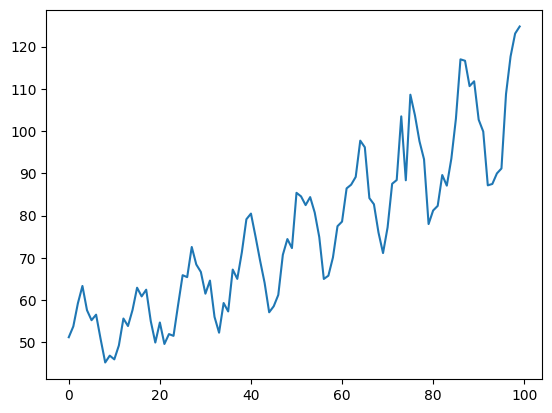

In [73]:
plt.plot(time_series)

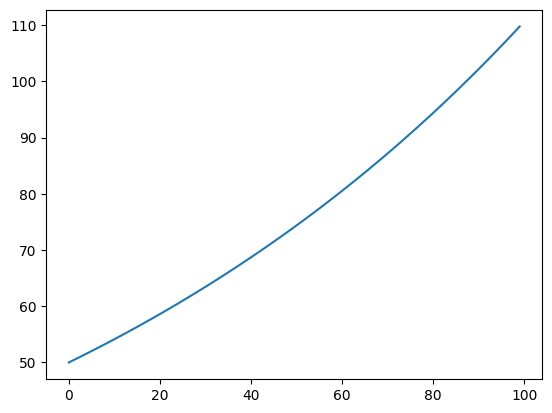

In [74]:
plt.plot(trend)

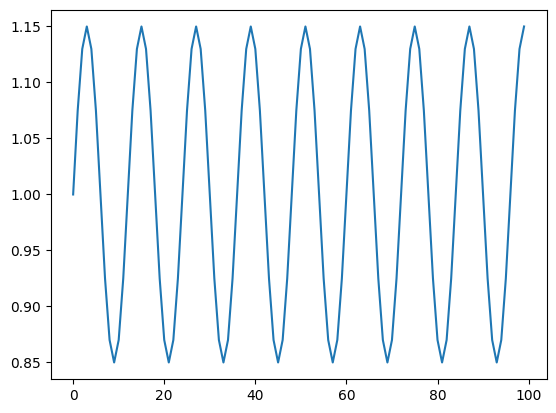

In [75]:
plt.plot(seasonal_factors)

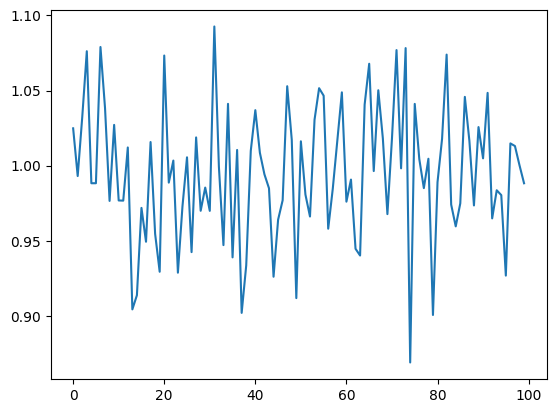

In [76]:
plt.plot(residual_factor)

## Real data - time series components

<Axes: xlabel='date'>

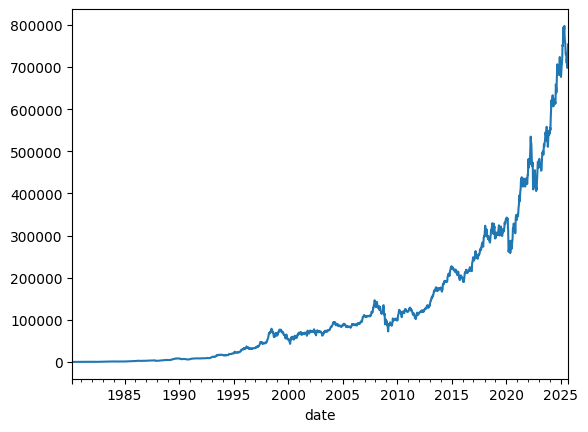

In [77]:
brk_week['open'].plot()

In [78]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL

In [79]:
brk_decomposed = seasonal_decompose(brk_week['open'], model = 'multiplicative')

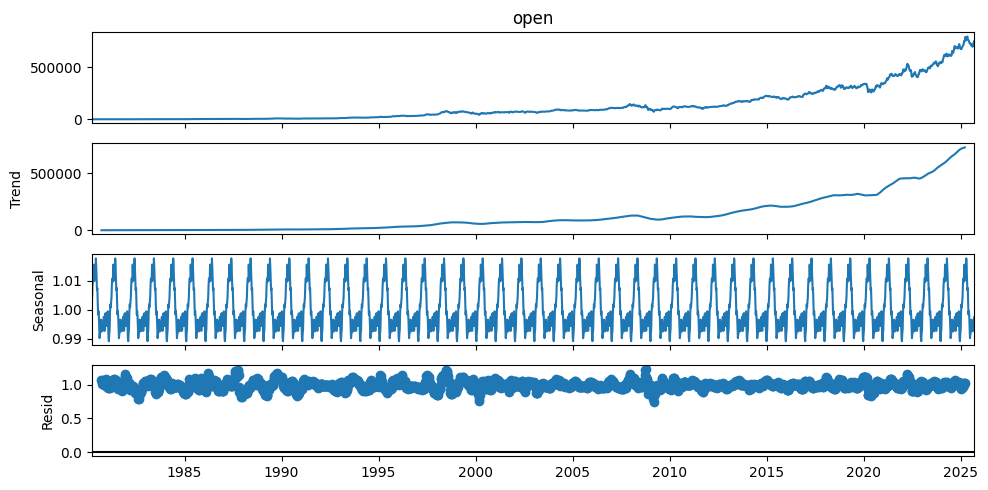

In [113]:
plt.rcParams['figure.figsize'] = (10,5)
brk_decomposed.plot();

- The first chart - The original observed data
- The trend shows an upward direction - positive(also can be negative or constant)
- The seasonal component shows the repeating pattern of highs and lows.
- The residual component shows the random variation in the data.

# Task 4

# Checking for Stationarity

Many forecasting techniques assume stationarity. That's why it is crucial to understand if the data we are working with is **stationary** or **non-stationary**.


A stationary time series doesn't have a trend or seasonality. Thus the data don't have patterns or specific statistical properties that vary over time. This kind of data makes the process easier to model and predict.

Non-stationary data contains patterns that might vary over time, making the modelling process more complex due to the dynamic nature of the data.

In [81]:
brk_week['open'].shape

(2374,)

https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.adfuller.html

In [82]:
from statsmodels.tsa.stattools import adfuller
ts = brk_week['open']
adfuller(ts)

(np.float64(6.052486708834706),
 1.0,
 26,
 2347,
 {'1%': np.float64(-3.4331392912353604),
  '5%': np.float64(-2.8627722587447804),
  '10%': np.float64(-2.5674259850221723)},
 np.float64(45350.66835133055))

In [83]:
# test statistic
# pvalue
# number of lags used to determine t-statistics
# number of lags used in the analysis
# t valus at 1%, 5%, 10%

# pvalue of 1 > 0.05 ===> The null hypothesis cannot be rejected.
# Hence data is non-stationary (it has relation with time)

# Detrending

## Differentiating

In [84]:
brk_week['prev_day_open'] = brk_week['open'].shift(1)

In [85]:
brk_week.head()

,open,high,low,close,volume,prev_day_open
date,,,,,,
1980-03-23,284.285714,304.285714,284.285714,284.285714,150.000000,NaN
1980-03-30,265.714286,285.714286,265.714286,265.714286,100.000000,284.285714
1980-04-06,261.071429,281.071429,261.071429,261.071429,142.857143,265.714286
1980-04-13,261.071429,281.071429,261.071429,261.071429,407.142857,261.071429
1980-04-20,253.571429,273.571429,253.571429,253.571429,178.571429,261.071429


In [86]:
brk_week['open_diff'] = brk_week['open'] - brk_week['prev_day_open']
brk_week

,open,high,low,close,volume,prev_day_open,open_diff
date,,,,,,,
1980-03-23,284.285714,304.285714,284.285714,284.285714,150.000000,NaN,NaN
1980-03-30,265.714286,285.714286,265.714286,265.714286,100.000000,284.285714,-18.571429
1980-04-06,261.071429,281.071429,261.071429,261.071429,142.857143,265.714286,-4.642857
1980-04-13,261.071429,281.071429,261.071429,261.071429,407.142857,261.071429,0.000000
1980-04-20,253.571429,273.571429,253.571429,253.571429,178.571429,261.071429,-7.500000
...,...,...,...,...,...,...,...
2025-08-17,712276.000000,716403.428571,707474.857143,712837.428571,352.142857,698136.857143,14139.142857
2025-08-24,729397.142857,732878.714286,724295.571429,729949.000000,308.714286,712276.000000,17121.142857
2025-08-31,742898.214286,749498.571429,739253.678571,746202.428571,346.214286,729397.142857,13501.071429


In [87]:
pvalue = adfuller(brk_week['open_diff'][1:])[1]
pvalue

np.float64(1.931818524578501e-17)

In [88]:
if pvalue > 0.05:
    print('data is non-stationary')
else:
    print('data is stationary')

data is stationary


# Task 5

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

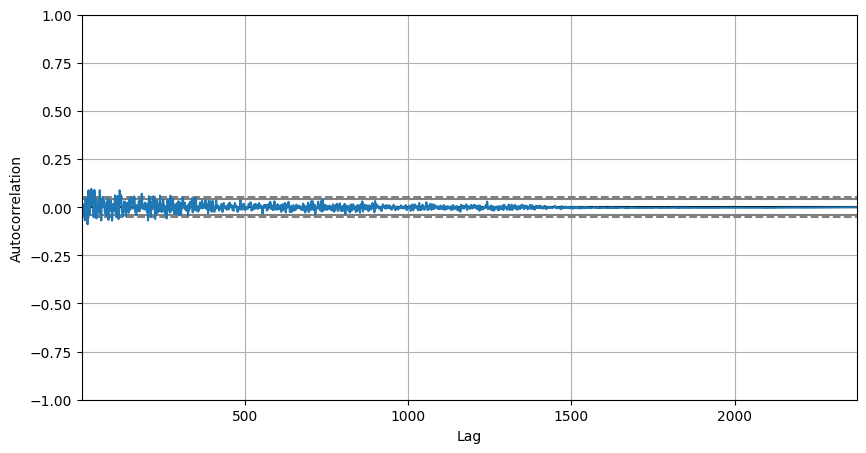

In [114]:
autocorrelation_plot(brk_week['open_diff'][1:])

<Axes: xlabel='date'>

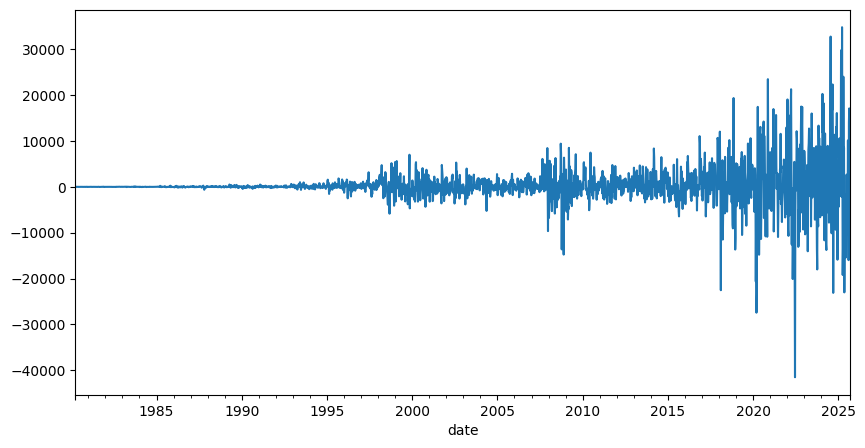

In [115]:
brk_week['open_diff'][1:].plot()

In [116]:
brk_week['open_diff'][1:].describe()

count     2373.000000
mean       312.115008
std       4088.708040
min     -41524.142857
25%       -385.714286
50%         15.000000
75%        892.857143
max      34831.142857
Name: open_diff, dtype: float64

<Axes: >

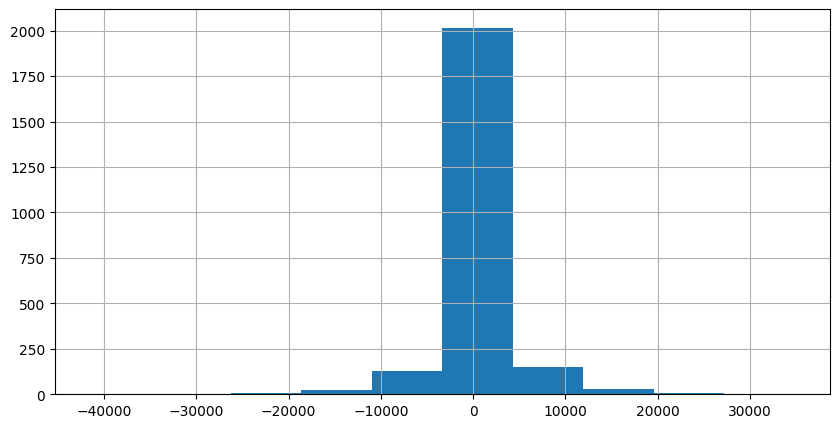

In [117]:
brk_week['open_diff'][1:].hist()

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

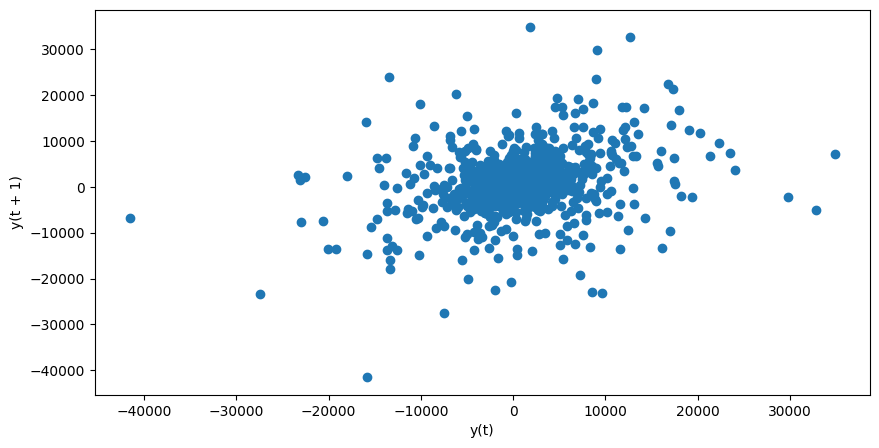

In [118]:
pd.plotting.lag_plot(brk_week['open_diff'][1:])

# White noise

## Example

In [94]:
import random

random.seed(1)
series = []
for i in range(1000):
    n = random.gauss(0, 1)
    series.append(n)

In [95]:
series

[1.2881847531554629,
 1.449445608699771,
 0.06633580893826191,
 -0.7645436509716318,
 -1.0921732151041414,
 0.03133451683171687,
 -1.022103170010873,
 -1.4368294451025299,
 0.19931197648375384,
 0.13337460465860485,
 0.5464683003382316,
 -0.9139709437353126,
 0.005005283626572444,
 -0.06474176037268789,
 -1.5058290012607418,
 0.5379971786610338,
 0.32071110099884825,
 2.389112043240686,
 0.20296917730996422,
 -0.14470230816492052,
 1.2327571750289237,
 0.1987912481934255,
 0.9090310261532091,
 -0.3655442662325168,
 0.21817181336058245,
 1.024288678487018,
 0.6962470224529616,
 0.1284722486328564,
 -1.0823080245960446,
 0.44522177236104854,
 0.07686348171925232,
 0.7204675968592537,
 0.21623293780007305,
 1.0881854111355231,
 -0.051560265423925424,
 0.20196406007942128,
 0.6667764386256495,
 -1.0868846121744795,
 -0.4016602600740189,
 -0.5000285689523685,
 1.980615719523246,
 -0.09286202565608458,
 0.652220223807572,
 0.619375062173719,
 -0.2808734301868926,
 -1.5508368271304471,
 0.964

In [96]:
series = pd.Series(series)
series.describe()

count    1000.000000
mean       -0.013222
std         1.003685
min        -2.961214
25%        -0.684192
50%        -0.010934
75%         0.703915
max         2.737260
dtype: float64

<Axes: >

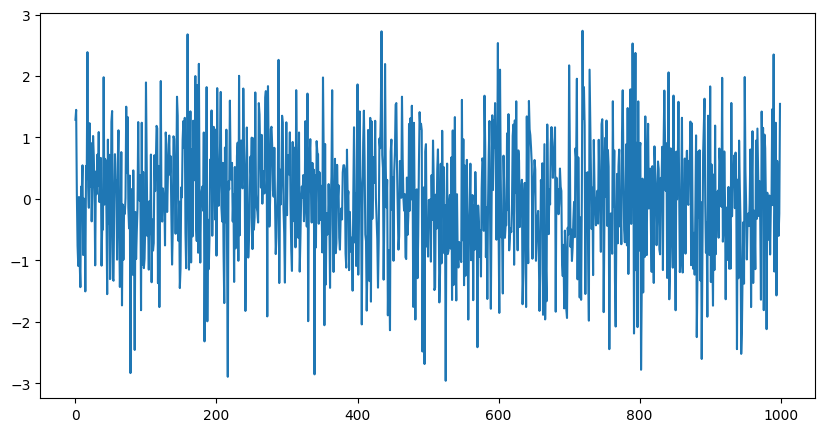

In [97]:
series.plot()

<Axes: >

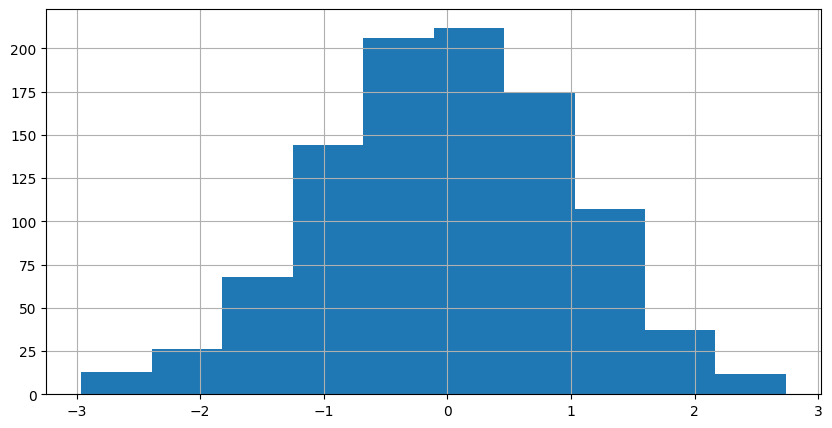

In [98]:
series.hist()

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

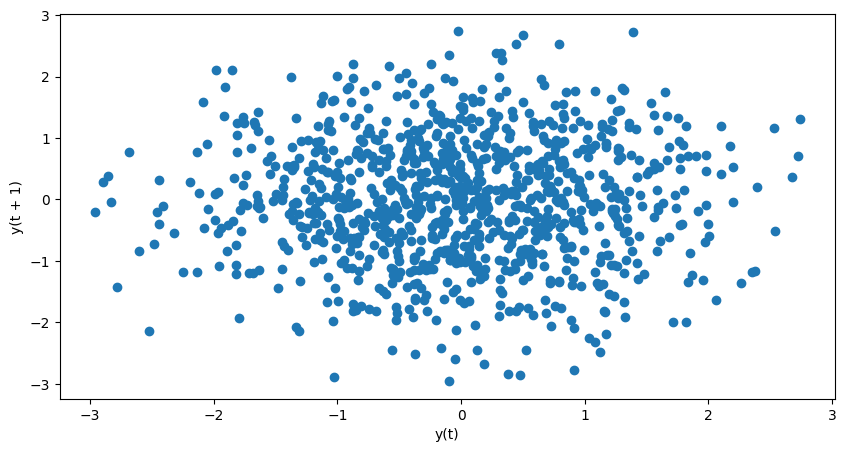

In [99]:
pd.plotting.lag_plot(series)

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

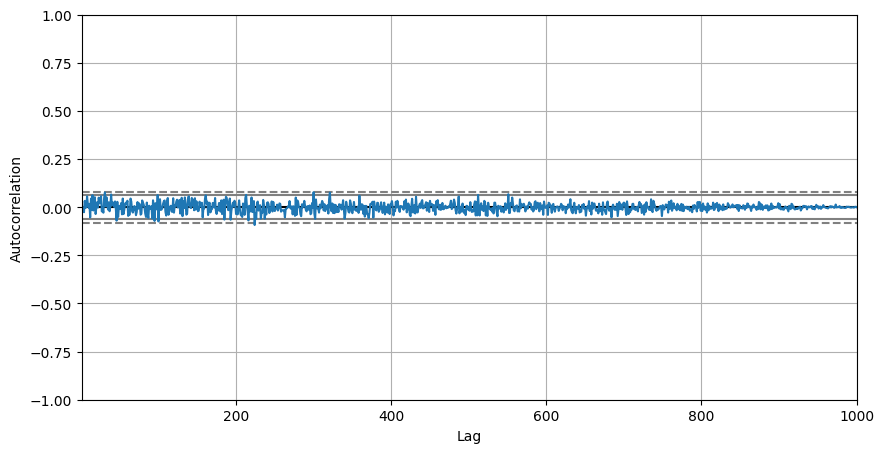

In [100]:
autocorrelation_plot(series)

# Random walk

In [101]:
random.seed(2021)
random_walk_values = []
random_walk_values.append(-1 if random.random() < 0.5 else 1)

for i in range(1, 1000):
    movement = -1 if random.random() < 0.5 else 1
    value = random_walk_values[i-1] + movement
    random_walk_values.append(value)

In [102]:
print(random_walk_values)

[1, 2, 3, 2, 3, 4, 3, 2, 1, 0, 1, 0, 1, 2, 3, 4, 3, 4, 3, 2, 3, 2, 3, 4, 3, 2, 1, 0, -1, -2, -1, -2, -3, -2, -3, -4, -5, -6, -5, -4, -5, -6, -5, -6, -5, -6, -5, -6, -7, -8, -7, -6, -5, -4, -3, -4, -5, -6, -7, -6, -5, -4, -5, -6, -5, -6, -5, -6, -5, -6, -5, -4, -5, -6, -5, -6, -7, -8, -7, -6, -7, -6, -7, -6, -7, -6, -5, -6, -5, -6, -7, -8, -9, -8, -9, -10, -9, -8, -9, -8, -7, -6, -7, -8, -9, -10, -11, -12, -13, -14, -13, -12, -11, -12, -11, -12, -13, -12, -13, -14, -15, -16, -17, -18, -19, -18, -19, -18, -17, -16, -15, -16, -15, -16, -17, -18, -17, -16, -15, -14, -13, -12, -11, -12, -11, -12, -13, -12, -13, -12, -11, -10, -9, -10, -11, -12, -11, -10, -11, -12, -13, -12, -11, -10, -11, -10, -9, -8, -9, -8, -7, -6, -7, -6, -5, -6, -7, -6, -7, -6, -5, -4, -3, -4, -3, -2, -1, 0, 1, 2, 3, 2, 3, 4, 3, 4, 3, 2, 3, 4, 3, 4, 3, 4, 5, 4, 3, 2, 3, 4, 3, 4, 5, 4, 5, 4, 3, 4, 5, 4, 3, 4, 5, 6, 7, 8, 7, 8, 9, 10, 9, 10, 9, 8, 9, 10, 11, 10, 11, 10, 9, 10, 11, 12, 13, 14, 13, 14, 15, 16, 15, 16, 15, 1

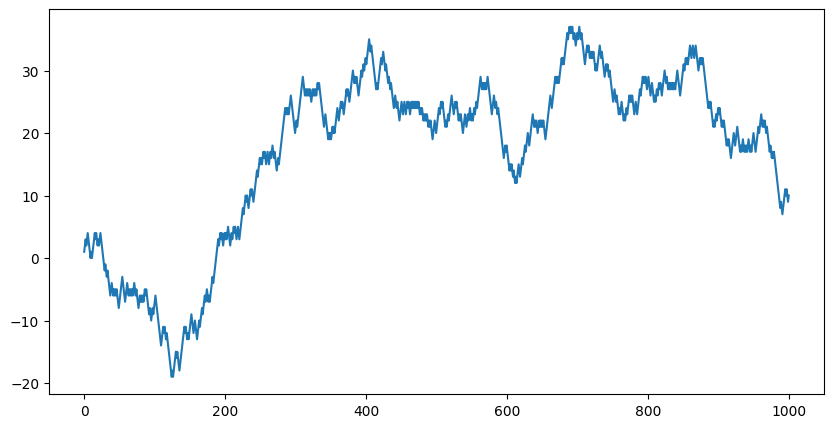

In [103]:
plt.plot(random_walk_values)

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

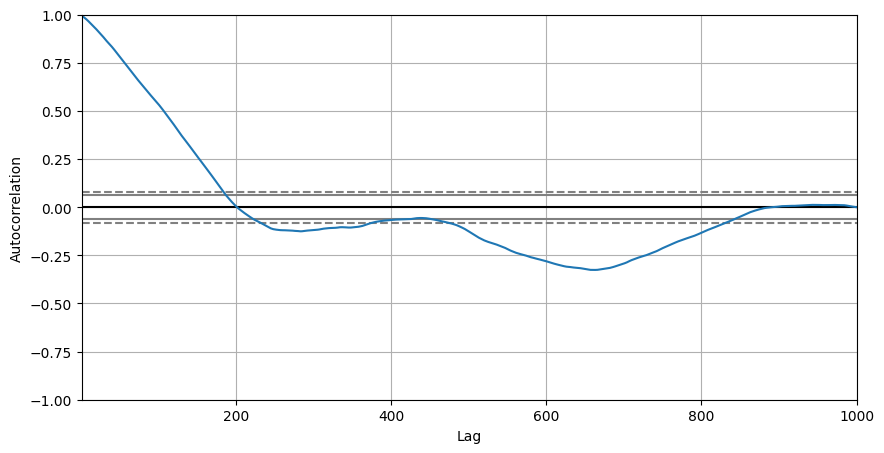

In [104]:
autocorrelation_plot(random_walk_values)

In [105]:
pvalue = adfuller(random_walk_values)[1]
pvalue

np.float64(0.616908897845108)

Differentiate the data to make it stationary.

In [106]:
if pvalue > 0.05:
    print('data is non-stationary')
else:
    print('data is stationary')

data is non-stationary


In [107]:
diff = []
for i in range(1, len(random_walk_values)):
    value = random_walk_values[i] - random_walk_values[i - 1]
    diff.append(value)

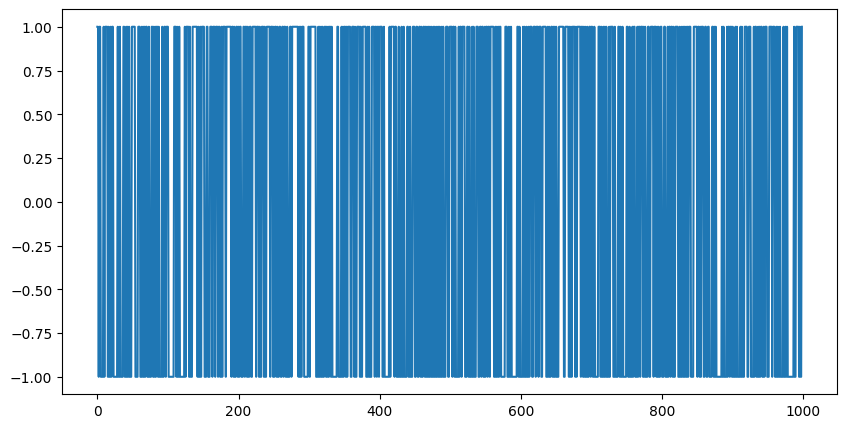

In [108]:
plt.plot(diff)

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

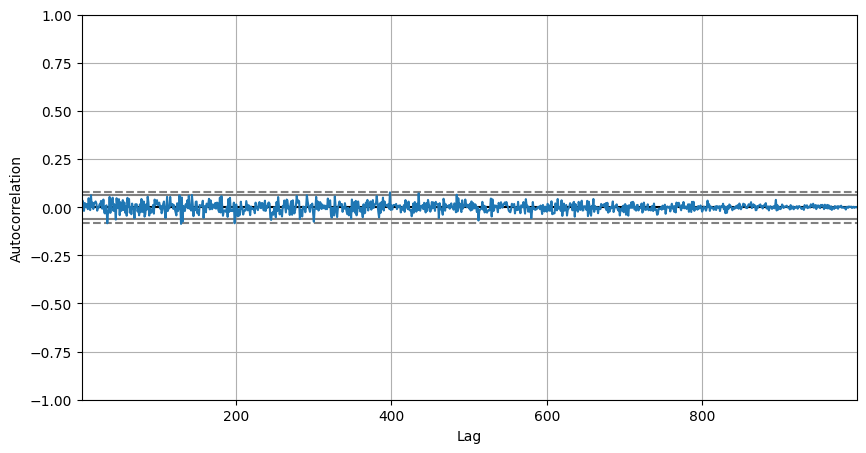

In [109]:
autocorrelation_plot(diff)

In [110]:
print(diff)

[1, 1, -1, 1, 1, -1, -1, -1, -1, 1, -1, 1, 1, 1, 1, -1, 1, -1, -1, 1, -1, 1, 1, -1, -1, -1, -1, -1, -1, 1, -1, -1, 1, -1, -1, -1, -1, 1, 1, -1, -1, 1, -1, 1, -1, 1, -1, -1, -1, 1, 1, 1, 1, 1, -1, -1, -1, -1, 1, 1, 1, -1, -1, 1, -1, 1, -1, 1, -1, 1, 1, -1, -1, 1, -1, -1, -1, 1, 1, -1, 1, -1, 1, -1, 1, 1, -1, 1, -1, -1, -1, -1, 1, -1, -1, 1, 1, -1, 1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, -1, 1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, 1, -1, 1, 1, 1, 1, -1, 1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, -1, 1, -1, -1, 1, -1, 1, 1, 1, 1, -1, -1, -1, 1, 1, -1, -1, -1, 1, 1, 1, -1, 1, 1, 1, -1, 1, 1, 1, -1, 1, 1, -1, -1, 1, -1, 1, 1, 1, 1, -1, 1, 1, 1, 1, 1, 1, 1, -1, 1, 1, -1, 1, -1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, -1, 1, 1, -1, 1, 1, -1, 1, -1, -1, 1, 1, -1, -1, 1, 1, 1, 1, 1, -1, 1, 1, 1, -1, 1, -1, -1, 1, 1, 1, -1, 1, -1, -1, 1, 1, 1, 1, 1, -1, 1, 1, 1, -1, 1, -1, 1, 1, -1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1, 1, 1, -1, -1, 1, -1, -1, -1, 1, 1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, 1, -1, 1,

In [111]:
pd.Series(diff).describe()

count    999.000000
mean       0.009009
std        1.000460
min       -1.000000
25%       -1.000000
50%        1.000000
75%        1.000000
max        1.000000
dtype: float64